# Data Analysis Pipeline — Industrial Alarm Data

This notebook contains the complete exploratory workflow for the alarm database: loading and cleaning, construction of the raw daily series, outlier treatment, descriptive EDA, calendar seasonality, operational gaps, inter-alarm recurrence, spectral analysis, additive decomposition, and correlation analysis.

Every alarm-only EDA module is executed here. Feature engineering remains in `build_feats_pipeline.ipynb`, and the discarded failure database is not used.

In [1]:
# LIBRARIES
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8')

# DATA PREPARATION AND TIME SERIES
from src.data_prep.db_preparation import load_db, sort_db, describe_db, clean_db
from src.data_prep.db_timeseries import (
    build_time_series,
    get_daily_counts,
    plot_daily_series,
    plot_series_by_year,
    remove_outliers_iqr,
)

# DESCRIPTIVE EDA
from src.eda.eda_analysis import (
    plot_value_counts,
    plot_grouped_countplot,
    pareto_analysis,
)

# NEW ALARM-ONLY EDA MODULES
from src.eda.eda_seasonality import (
    analyze_calendar_seasonality,
    plot_calendar_seasonality,
)
from src.eda.eda_gaps import (
    identify_gaps,
    classify_gaps,
    gap_summary,
    plot_gaps_overview,
    plot_classified_gap_series,
)
from src.eda.eda_interalarm import (
    inter_alarm_statistics,
    plot_inter_alarm_overview,
)
from src.eda.eda_recurrence import (
    build_recurrence_analysis,
    plot_recurrence_rate,
    plot_recurrence_thresholds,
    plot_recurrence_by_shift,
)
from src.eda.eda_spectral import (
    compute_fft_spectrum,
    summarize_frequency_bands,
    plot_power_spectrum,
    plot_conditional_patterns,
)
from src.eda.eda_decomposition import (
    compute_additive_decomposition,
    decomposition_summary,
    plot_additive_decomposition,
)

# CORRELATIONS
from src.eda.eda_correlations import (
    n_cols_correlation,
    x_y_correlation,
    plot_acf_pacf,
    acf_by_year_heatmap,
)
from src.eda.eda_exogen_variables import (
    monthly_alarm_counts,
    load_gdp,
    load_selic,
    load_trade_balance,
    load_ipca_duraveis,
    correlation_pvalue,
    plot_regression,
    lag_correlation_analysis,
)

# DATA PATHS
DATA_PATH = 'src/data/'
ALARMS_FILE = DATA_PATH + 'alarmescompletos.csv'
GDP_FILE = DATA_PATH + 'pib2019a2025.csv'
SELIC_FILE = DATA_PATH + 'selic2019a2025.csv'
TRADE_BALANCE_FILE = DATA_PATH + 'balancacomercial2019a2025.csv'
IPCA_DURAVEIS_FILE = DATA_PATH + 'ipca_duraveis_serie.csv'

## 1. Load & Clean Raw Data

In [2]:
df_alarms_raw = load_db(ALARMS_FILE)

sort_db(df_alarms_raw, 'TIMESTAMP')
describe_db(df_alarms_raw)

DATABASE HEADER
  Shop Line    ST   Maq  Bilancella  Trato  Fault_Code1  Fault_Code2  \
0  BiW  TDF  MAIN  TR14          14     16            0            0   
1  BiW  TDF  MAIN  TR10          10      9            0            0   
2  BiW  TDF  MAIN  TR03           3     10            0            0   

   Fault_Code3  Posicao                       TIMESTAMP  
0           32   208549  2025-05-16 13:40:05.150000 UTC  
1           32   167149  2025-05-16 13:40:05.132000 UTC  
2           32        0  2025-05-16 13:40:05.069000 UTC  

DATABASE SHAPE
(88414, 11)

DATABASE INFO
<class 'pandas.DataFrame'>
RangeIndex: 88414 entries, 0 to 88413
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Shop         88414 non-null  str     
 1   Line         88414 non-null  str     
 2   ST           88414 non-null  str     
 3   Maq          88414 non-null  str     
 4   Bilancella   88414 non-null  int64   
 5   Trato        884

In [3]:
df_series = df_alarms_raw.copy()
df_series = clean_db(df_series)

[LOG] Columns lowered:  ['shop', 'line', 'st', 'maq', 'bilancella', 'trato', 'fault_code1', 'fault_code2', 'fault_code3', 'posicao', 'timestamp']
[LOG] Duplicates removed: 3
[LOG] Columns stripped: ['shop', 'line', 'st', 'maq', 'bilancella', 'trato', 'fault_code1', 'fault_code2', 'fault_code3', 'posicao', 'timestamp']
[LOG] NaNs removed: 0
[LOG] Total lines: 88414 -> 88411 (3 lines removed)


## 2. Build the Daily Time Series

### 2.1 Raw Daily Aggregate Data

In [4]:
df_series_datetime = build_time_series(df_series, timestamp_col='timestamp')
daily_agg_time_series = get_daily_counts(df_series_datetime, timestamp_col='timestamp')

[LOG] Rows dropped due to invalid 'timestamp'/NaNs: 0
[LOG] Time series sorted: 2020-01-11 12:47:33.927000+00:00 -> 2025-05-16 13:47:42.084000+00:00
[LOG] Daily series length: 1953 (1528 days with data, 425 empty days)


[LOG] Plot saved to: results/time_series/daily_agg_raw_time_series.png


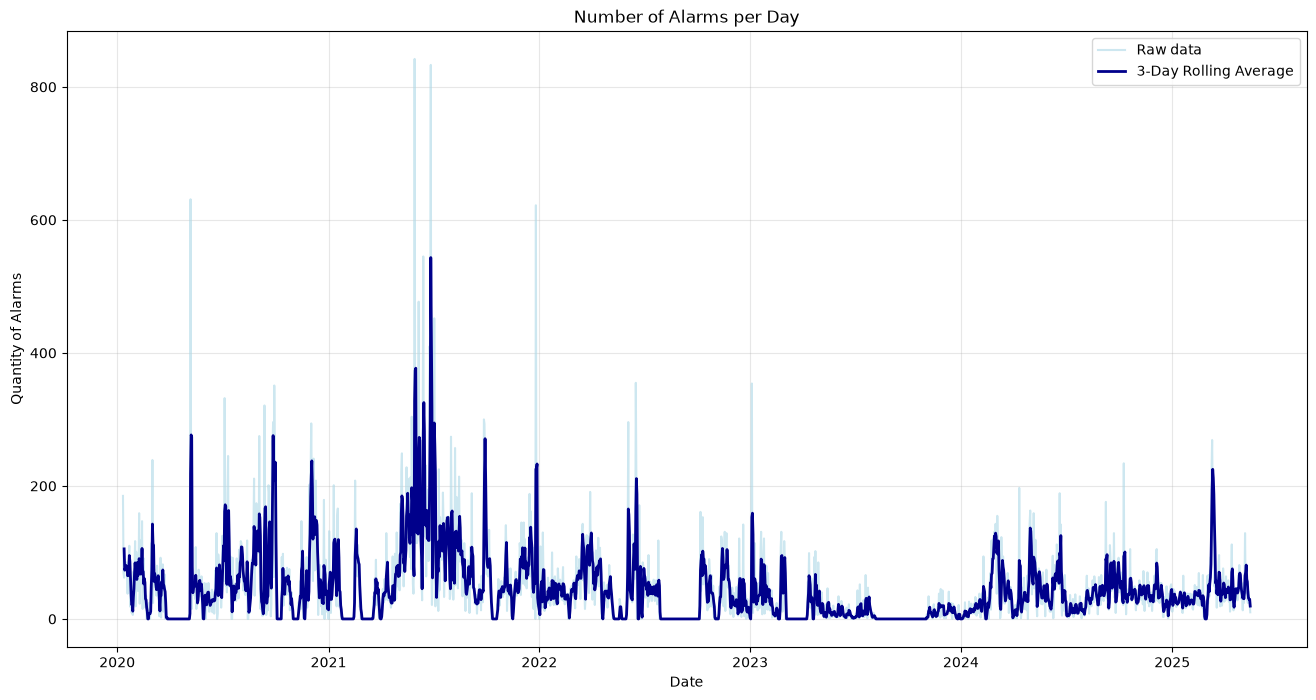

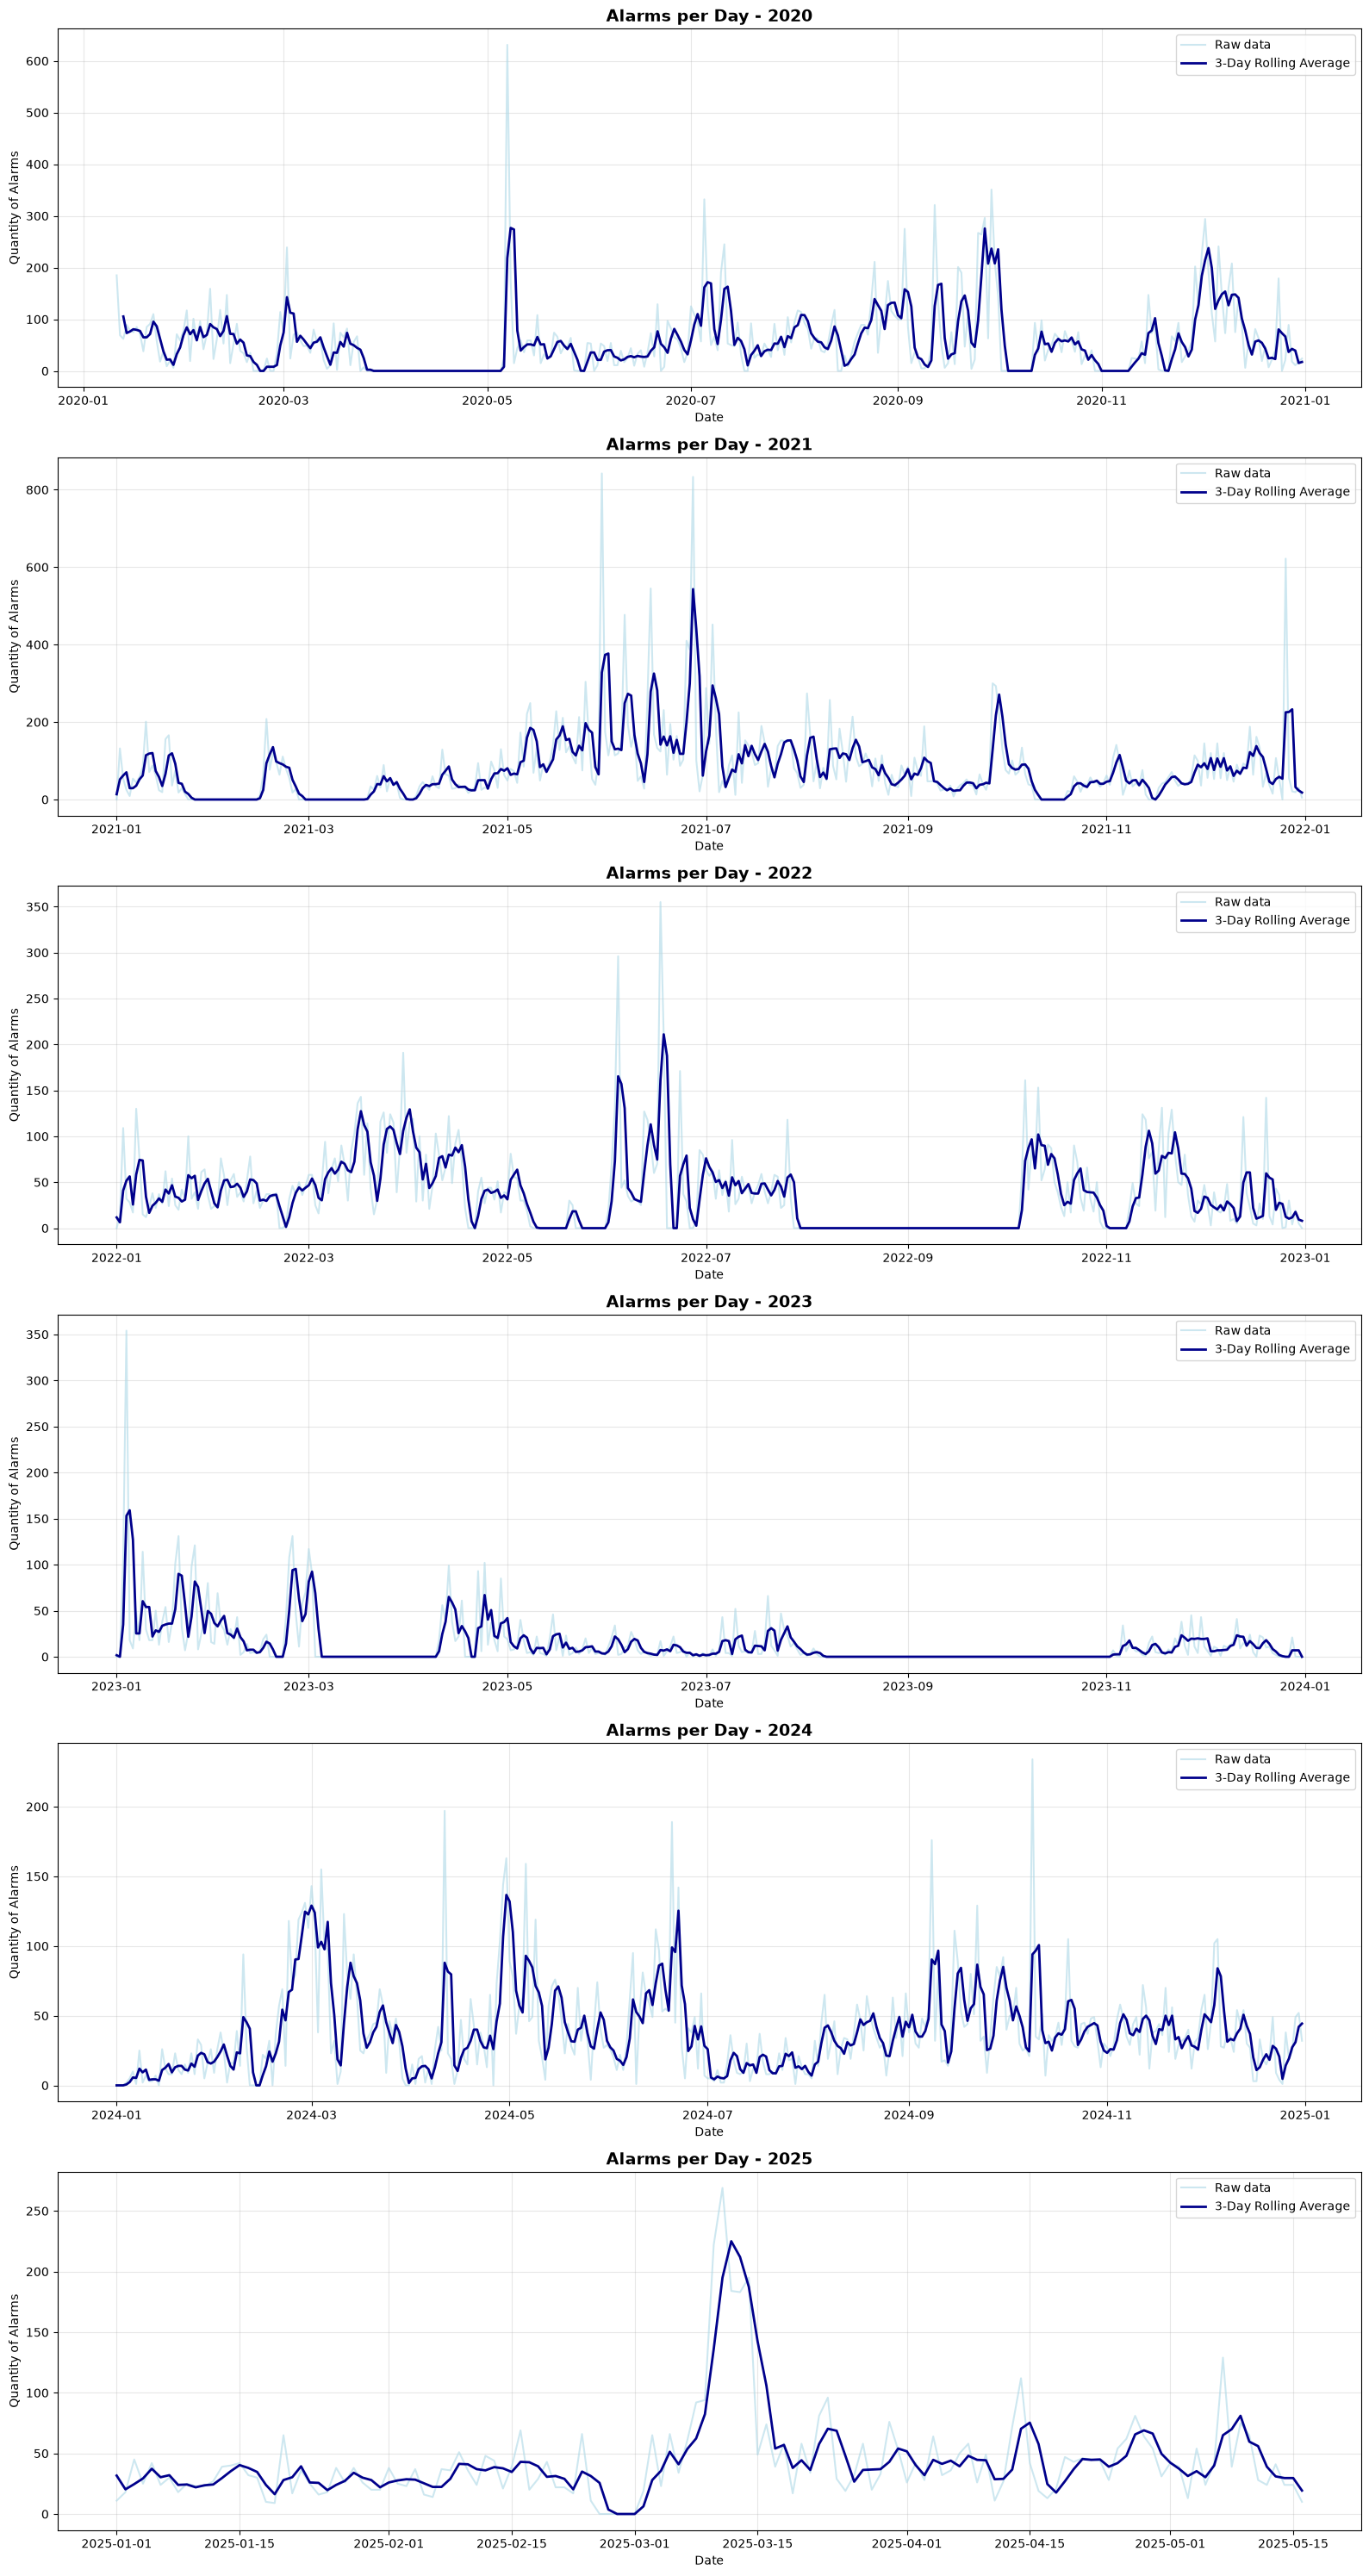

In [5]:
_ = plot_daily_series(daily_agg_time_series, save_path="results/time_series/daily_agg_raw_time_series.png")
plot_series_by_year(daily_agg_time_series, save_path="results/time_series/daily_agg_raw_time_series_by_year.png")

### 2.2 Outliers removed Daily Agg. Data

In [6]:
daily_agg_ts_no_outliers, _ = remove_outliers_iqr(daily_agg_time_series)

[LOG] 106 outlier(s) interpolated


[LOG] Plot saved to: results/time_series/daily_agg_raw_ts_no_outliers.png


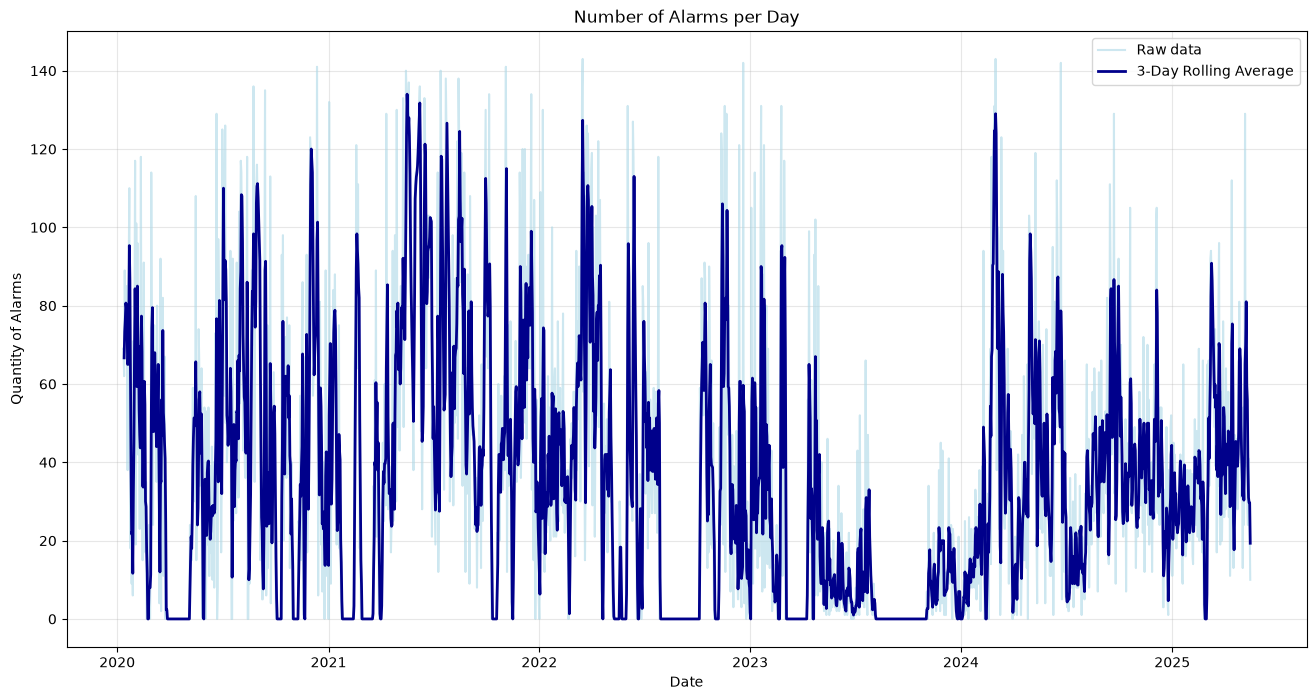

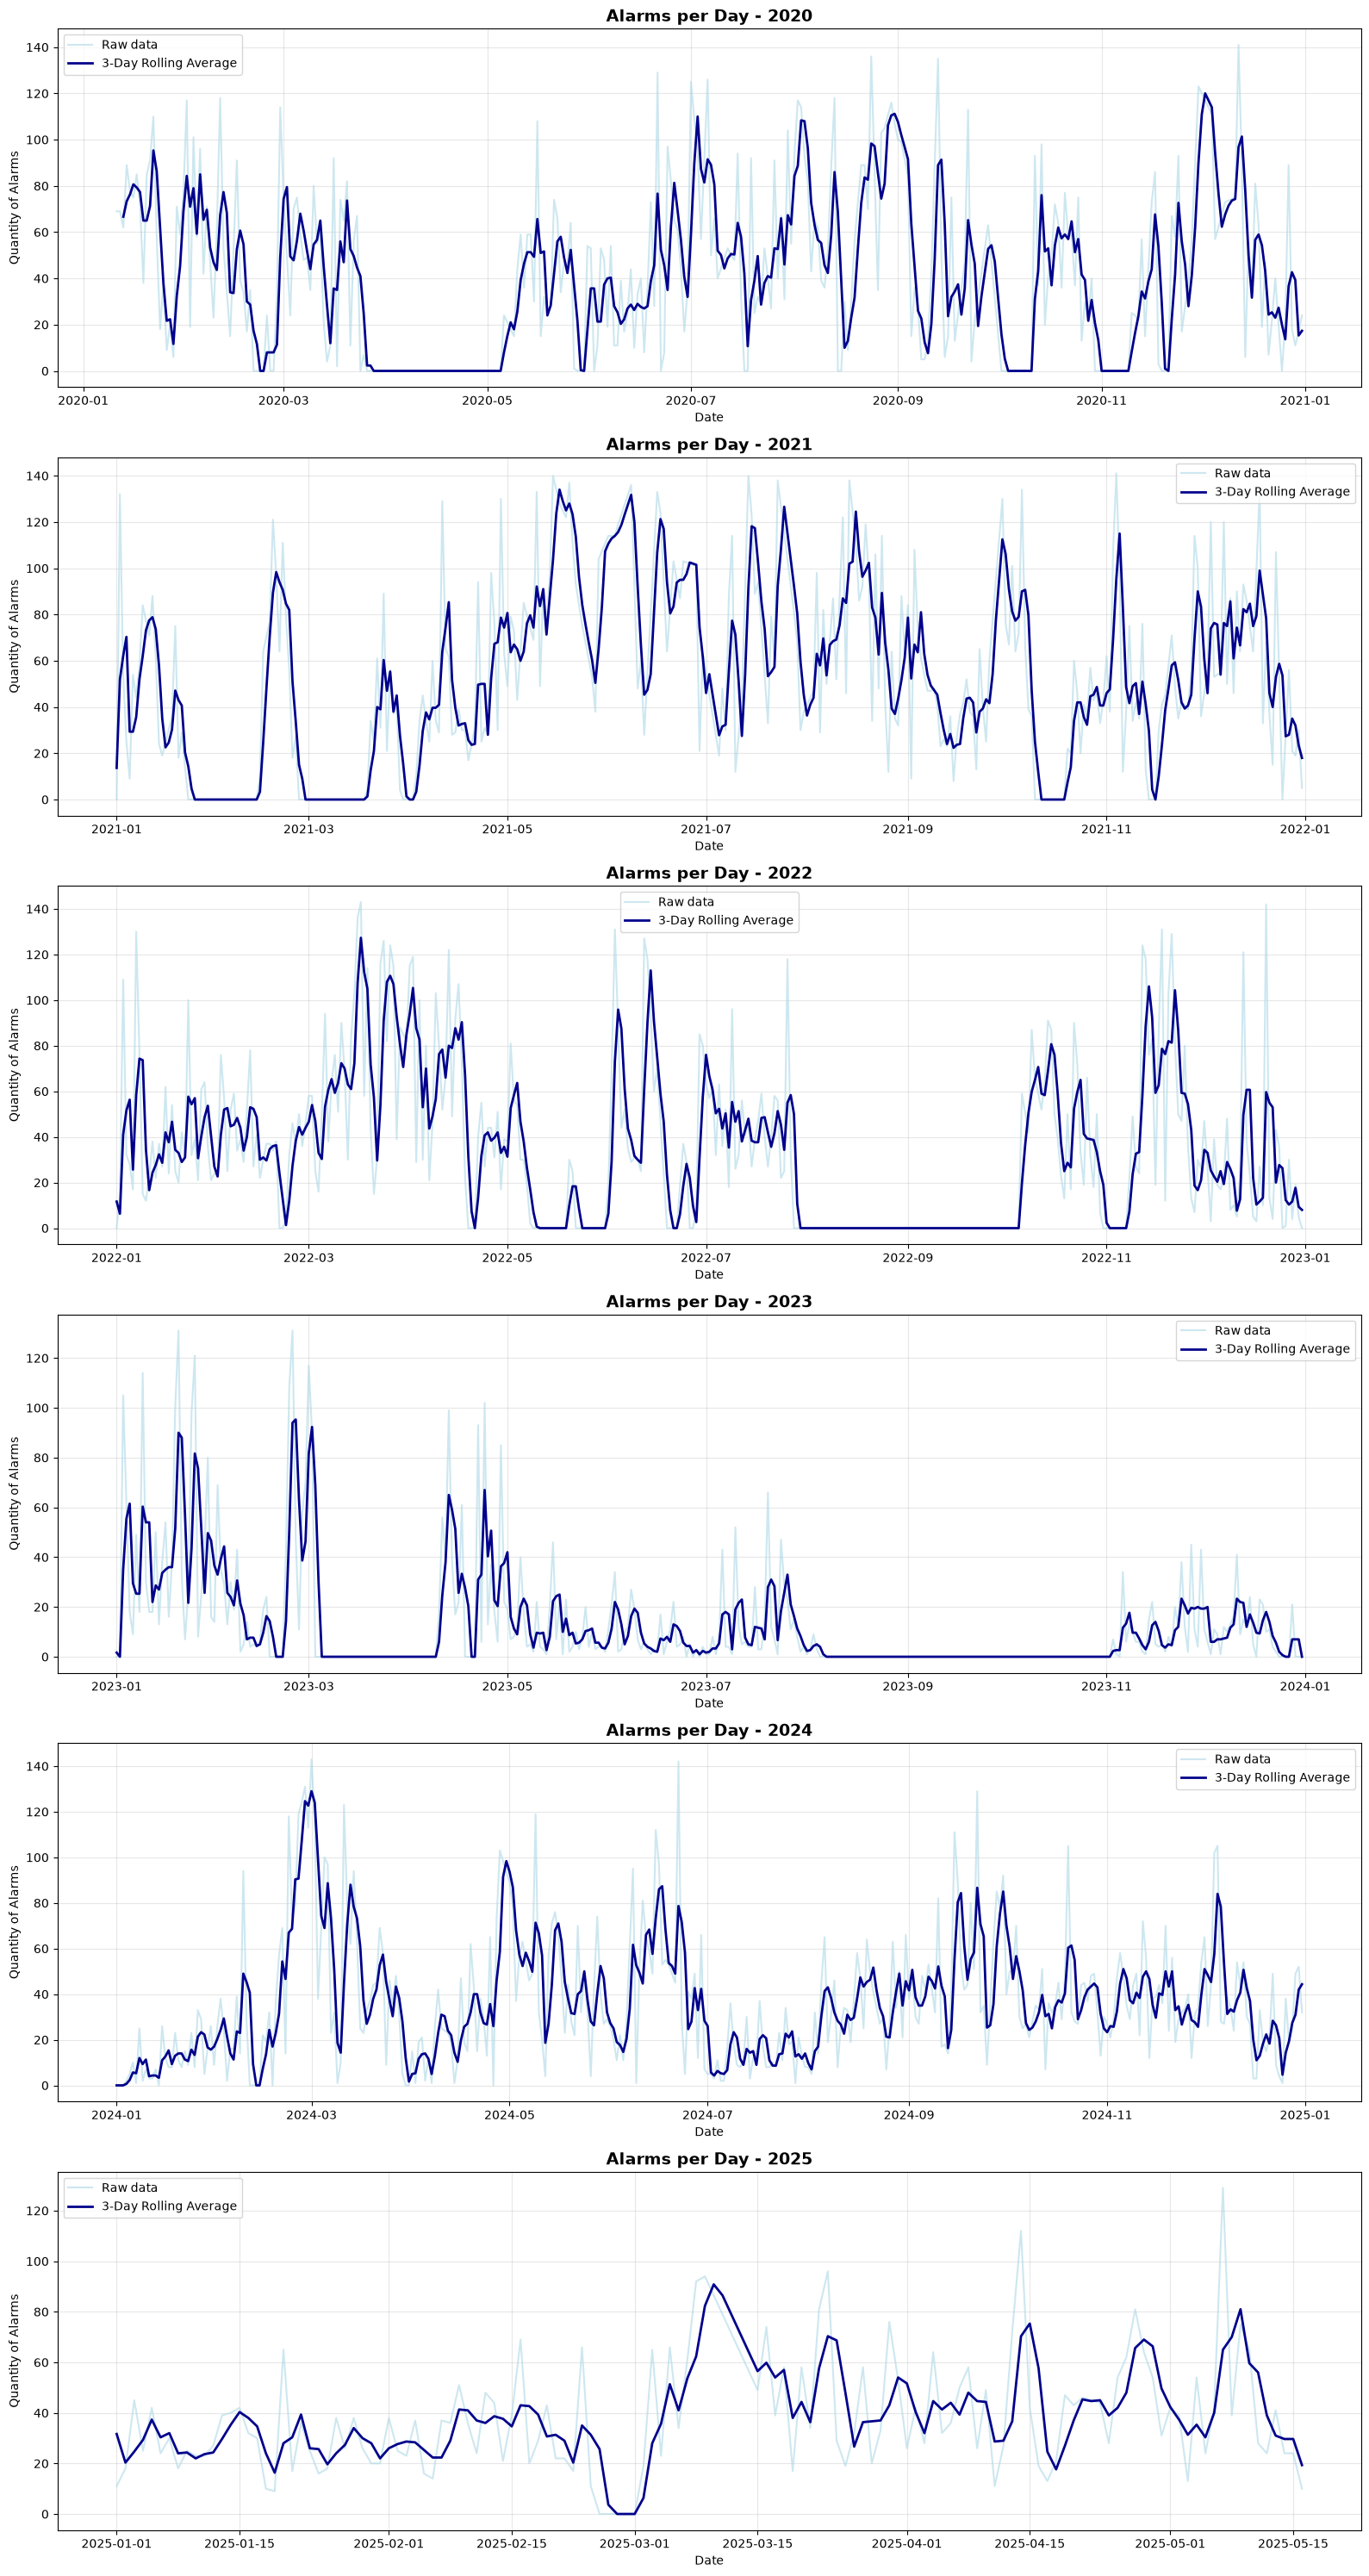

In [7]:
_ = plot_daily_series(daily_agg_ts_no_outliers, save_path="results/time_series/daily_agg_raw_ts_no_outliers.png")
plot_series_by_year(daily_agg_ts_no_outliers, save_path="results/time_series/daily_agg_raw_ts_no_outliers_by_year.png")

## 3. Exploratory Data Analysis

### 3.1 Categorical Distributions
['shop', 'line', 'st', 'maq', 'bilancella', 'trato', 'fault_code1', 'fault_code2', 'fault_code3', 'posicao']

[LOG] Counts by 'line':
line
TDF    50368
TLF    38043
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/line_value_counts.png


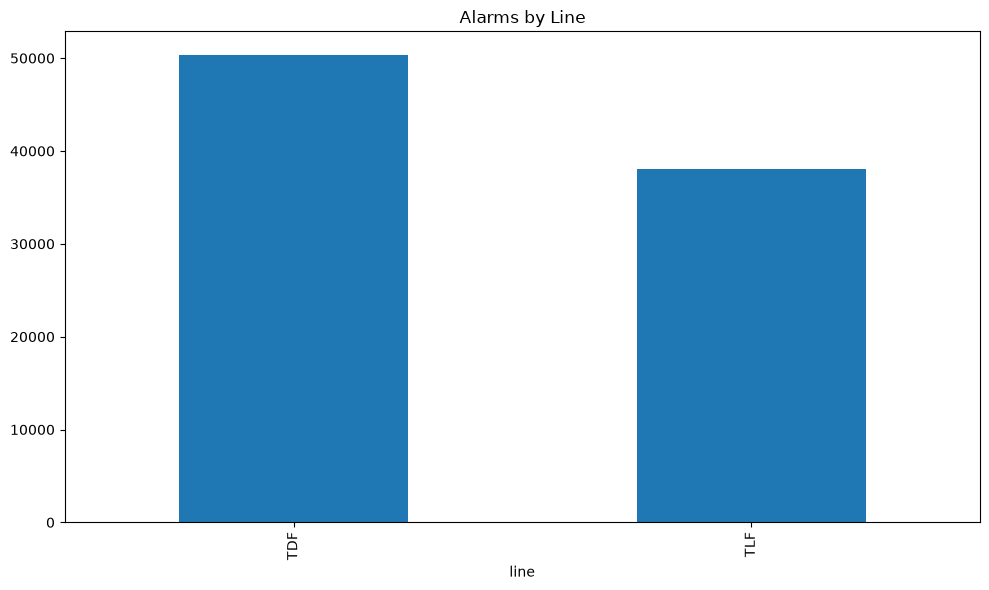

In [8]:
_ = plot_value_counts(df_series_datetime, column='line', title='Alarms by Line', save_path="results/eda/value_counts/line_value_counts.png")

[LOG] Counts by 'shop':
shop
BiW    88411
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/shop_value_counts.png


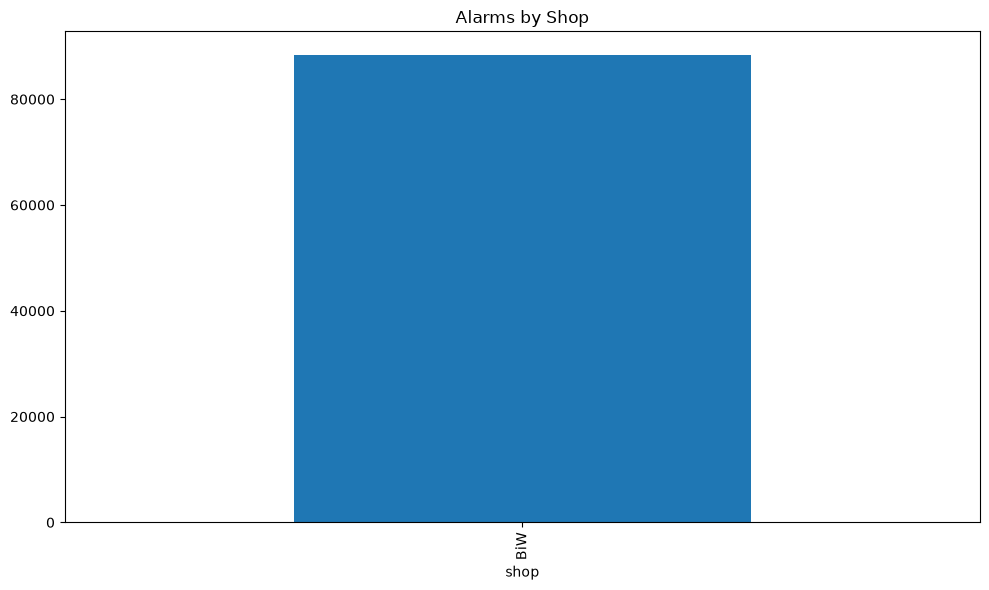

In [9]:
_ = plot_value_counts(df_series_datetime, column='shop', title='Alarms by Shop', save_path="results/eda/value_counts/shop_value_counts.png")

[LOG] Counts by 'st':
st
MAIN    88411
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/st_value_counts.png


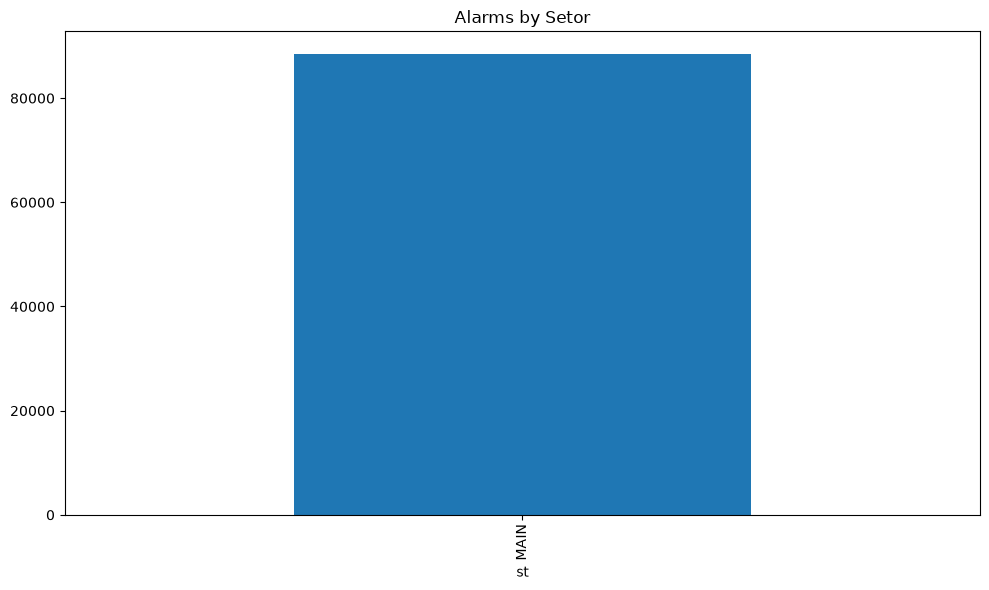

In [10]:
_ = plot_value_counts(df_series_datetime, column='st', title='Alarms by Setor', save_path="results/eda/value_counts/st_value_counts.png")

[LOG] Counts by 'maq':
maq
TR01    5056
TR02    4136
TR03    4558
TR04    4810
TR05    2010
TR06    4717
TR07    4690
TR08    4966
TR09    4879
TR10    6379
TR11    4997
TR12    4629
TR13    4906
TR14    3967
TR15    4506
TR16    1639
TR17    5527
TR18    3279
TR19    4957
TR20    3803
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/maq_value_counts.png


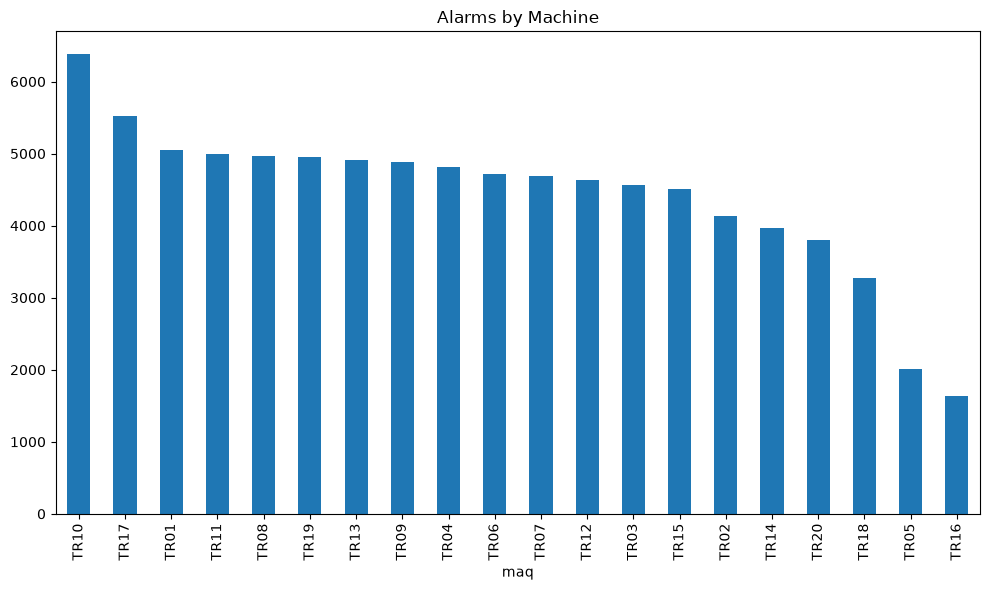

In [11]:
_ = plot_value_counts(df_series_datetime, column='maq', title='Alarms by Machine', save_path="results/eda/value_counts/maq_value_counts.png")

[LOG] Counts by 'bilancella':
bilancella
0      223
1     5101
2      830
3     4522
4     4807
5     5256
6     4714
7     4687
8     4963
9     4876
10    6376
11    4994
12    4626
13    4903
14    2157
15    4475
16    1466
17    5525
18    5053
19    4944
20    3776
43       3
47      10
48       1
49       2
50      68
52       2
53      50
55       1
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/bilancella_value_counts.png


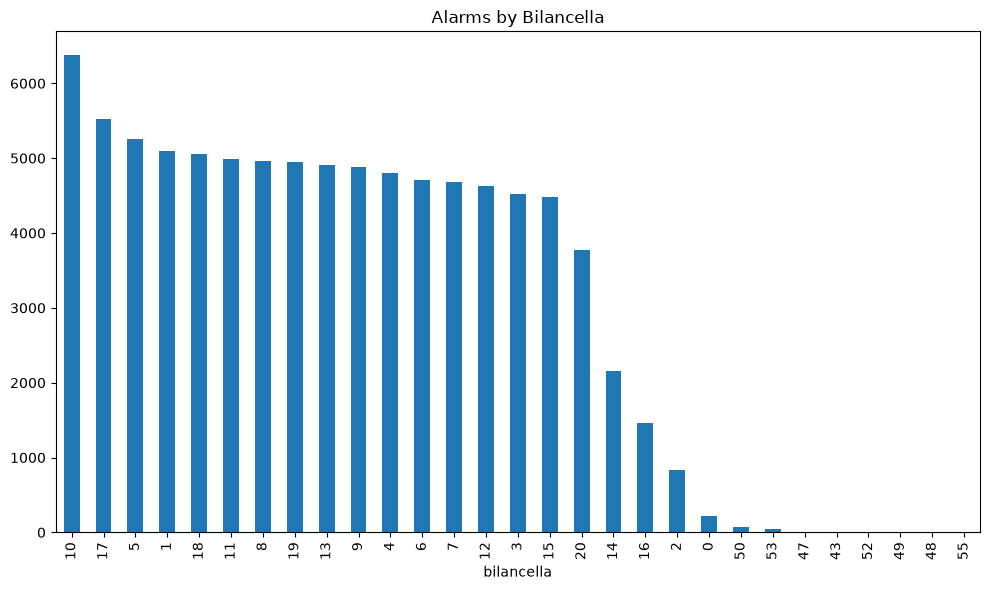

In [12]:
_ = plot_value_counts(df_series_datetime, column='bilancella', title='Alarms by Bilancella', save_path="results/eda/value_counts/bilancella_value_counts.png")

[LOG] Counts by 'trato':
trato
0       100
1      1115
2      1200
3      1733
4      1234
5      1417
6      2197
7      2191
8       773
9      1906
10     1483
11     1557
12     1851
13     2223
14     2229
15     2422
16     2706
17     3127
18    13160
19      181
20     2034
21     2207
22     2917
23     3261
24     2573
25     2332
26    15962
27      145
28      727
29     1554
30     3032
31      863
32     1235
33     1270
34     1104
35     1421
36       76
37      269
38      110
99      514
dtype: int64
[LOG] Plot saved to: results/eda/value_counts/trato_value_counts.png


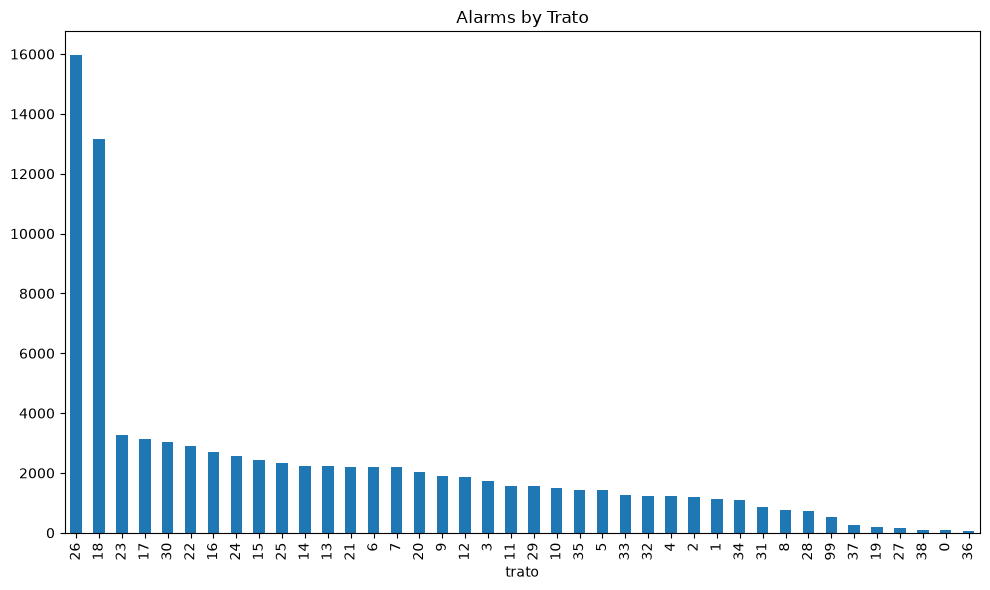

In [13]:
_ = plot_value_counts(df_series_datetime, column='trato', title='Alarms by Trato', save_path="results/eda/value_counts/trato_value_counts.png")

### 3.2 X by Y Distributions

[LOG] Plot saved to: results/eda/grouped_countplots/line_x_machine.png


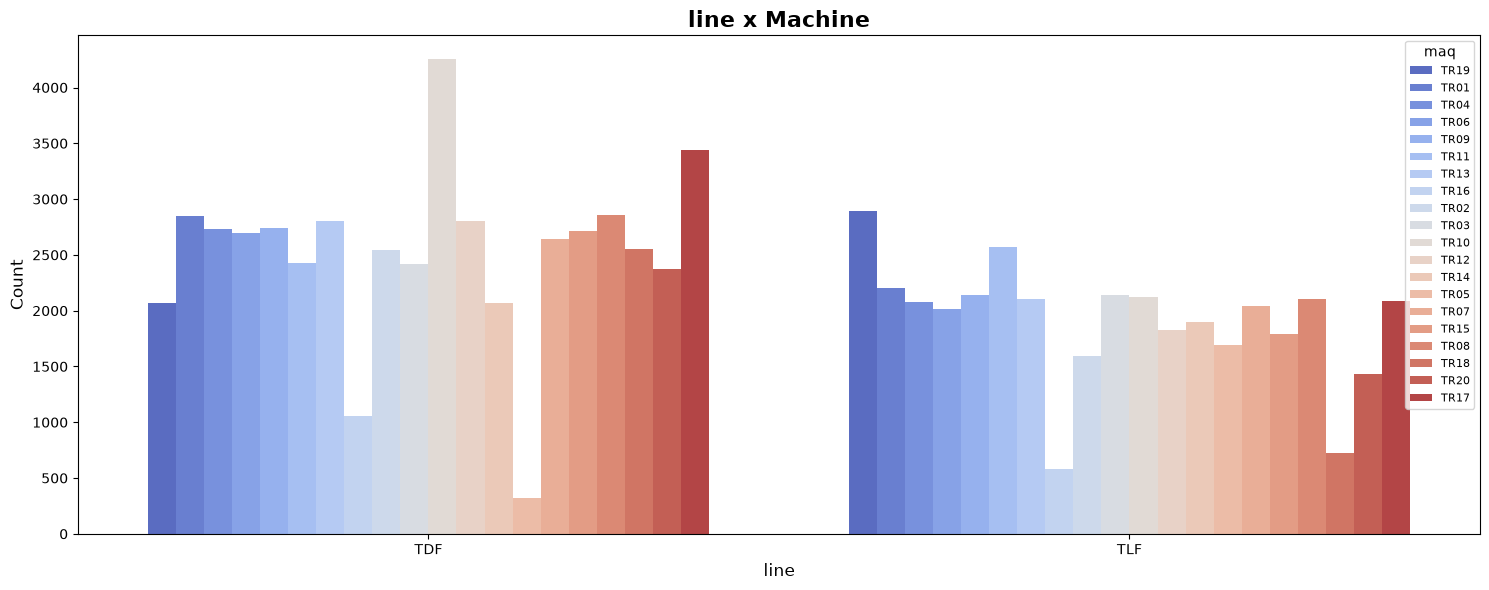

[LOG] Plot saved to: results/eda/grouped_countplots/fault_code1_x_machine.png


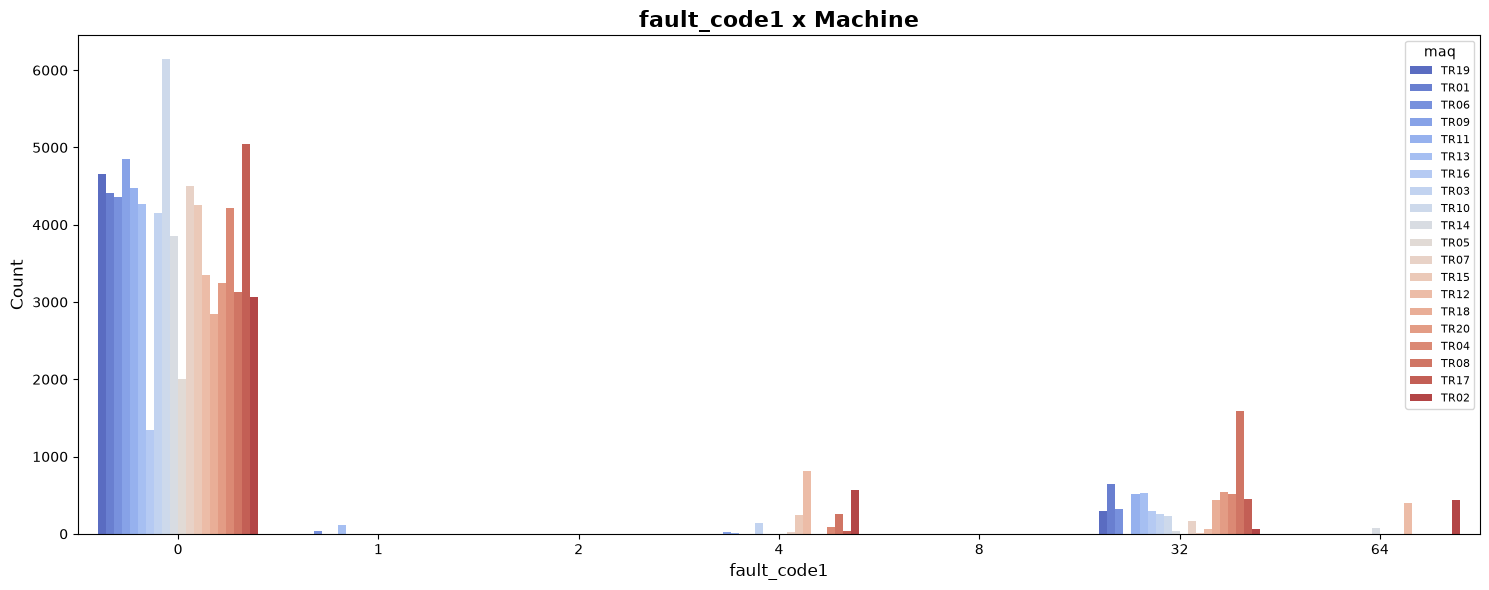

[LOG] Plot saved to: results/eda/grouped_countplots/fault_code2_x_machine.png


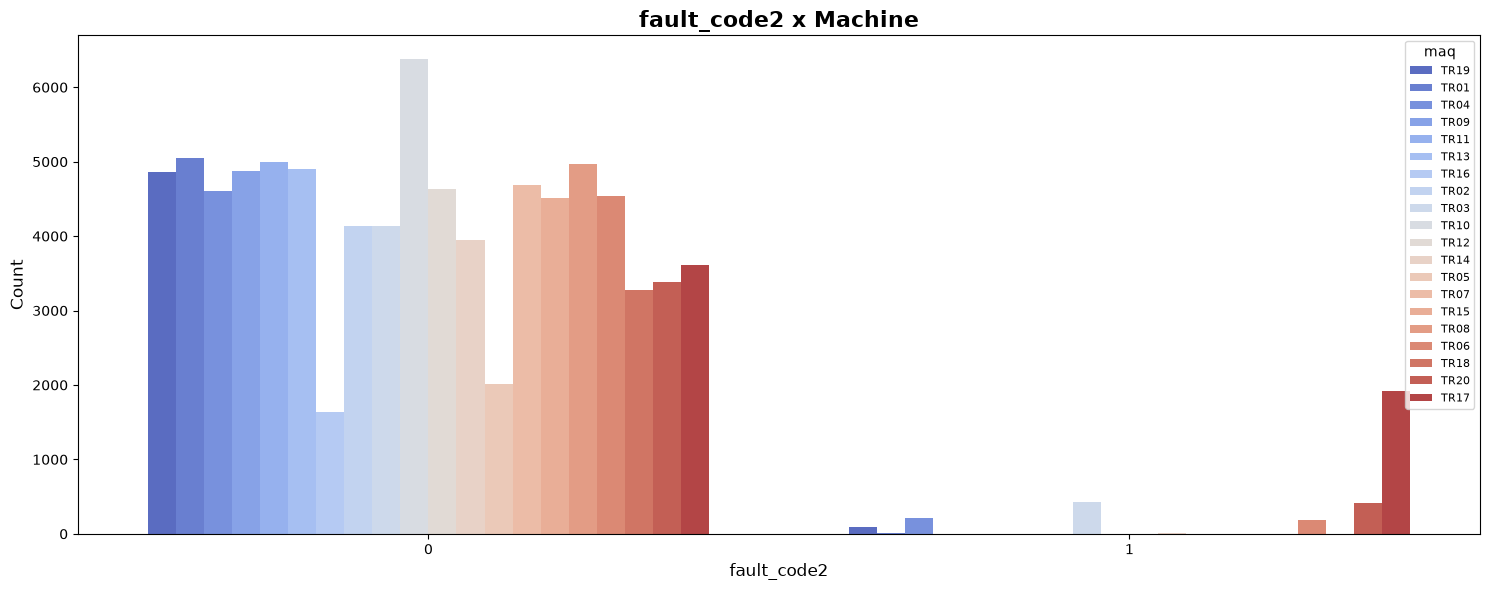

[LOG] Plot saved to: results/eda/grouped_countplots/fault_code3_x_machine.png


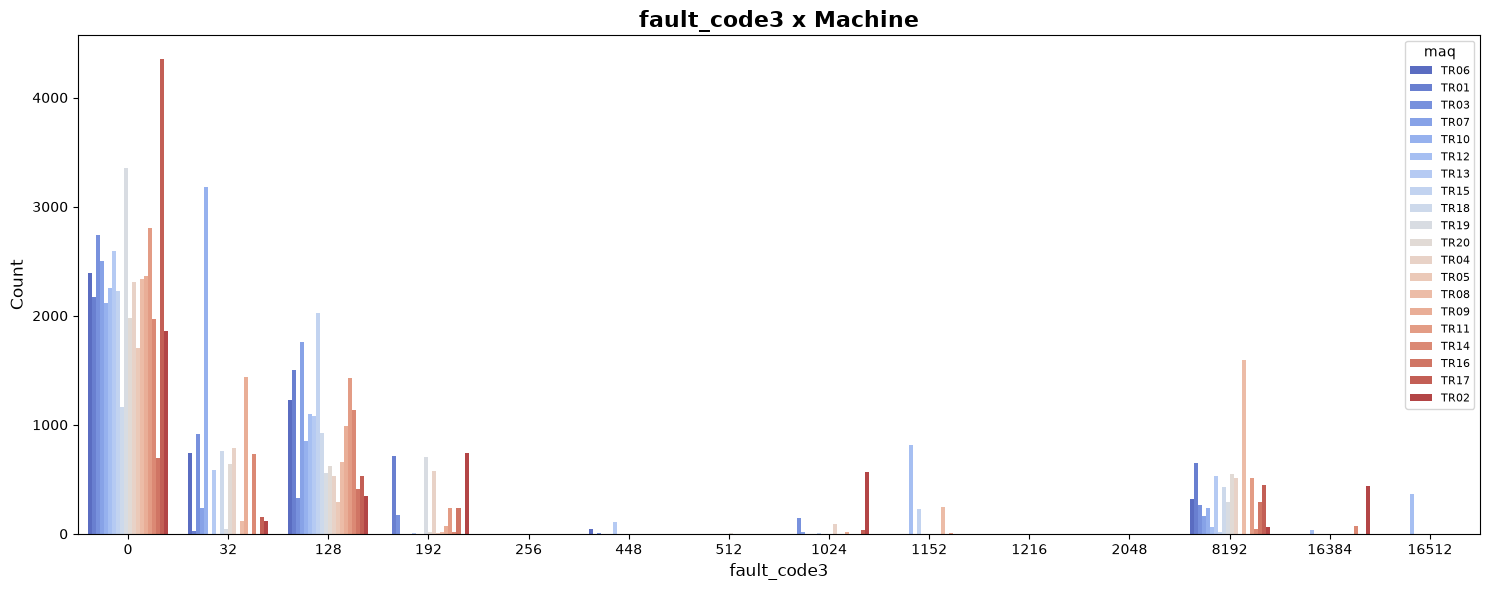

[LOG] Plot saved to: results/eda/grouped_countplots/bilancella_x_machine.png


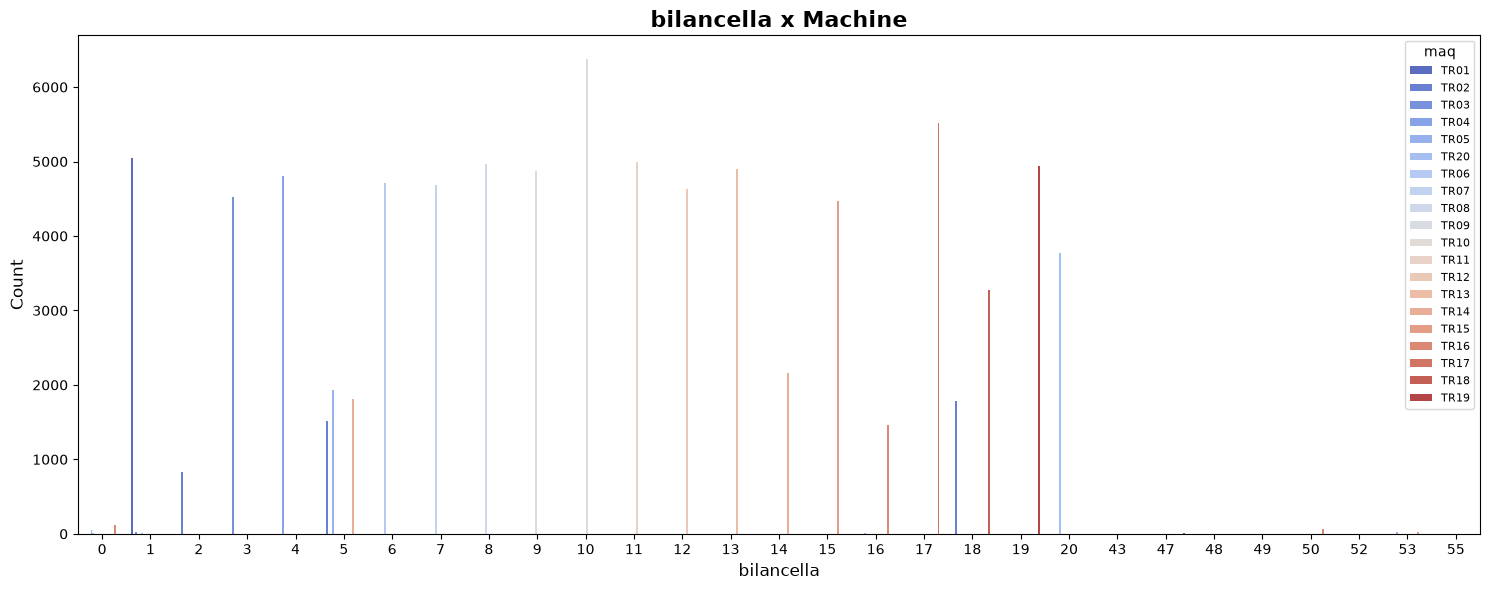

[LOG] Plot saved to: results/eda/grouped_countplots/trato_x_machine.png


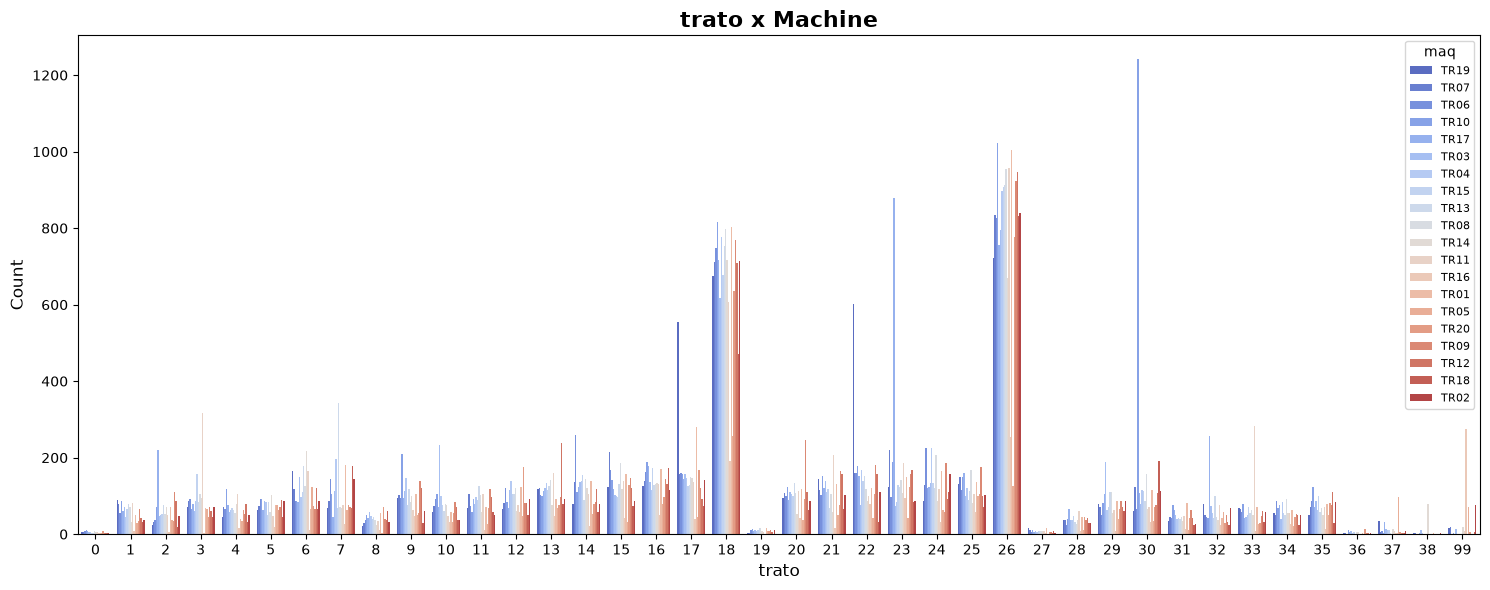

In [14]:
for col in ['line', 'fault_code1', 'fault_code2', 'fault_code3', 'bilancella', 'trato']:
    plot_grouped_countplot(
        df_series_datetime,
        x=col,
        hue='maq',
        title=f'{col} x Machine',
        save_path=f'results/eda/grouped_countplots/{col}_x_machine.png',
    )

### 3.3 Machine Pareto Analysis

[LOG] Pareto (maq): top 20 of 20 categories cover 100.0% of records
[LOG] Plot saved to: results/eda/pareto_maq.png


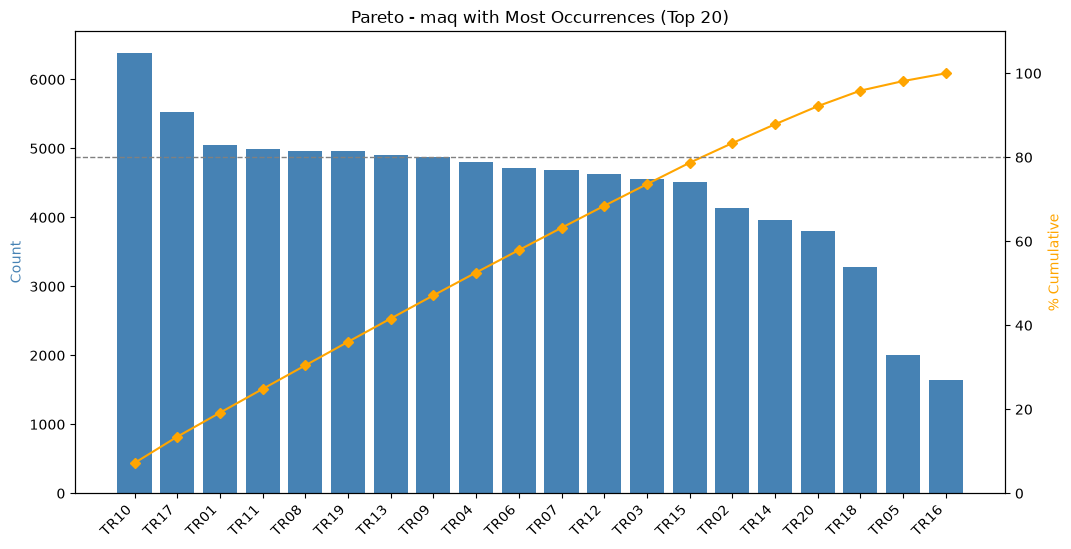

In [15]:
pareto_df_maq = pareto_analysis(df_series_datetime, column='maq', top_n=20, save_path="results/eda/pareto_maq.png")

### 3.4 Calendar Seasonality

Intraday seasonality uses the raw row-level time-series dataset because hour and machine information is not present after daily aggregation. Weekly and monthly seasonal patterns are evaluated on both the raw daily series and its outlier-free counterpart.

[LOG] Calendar columns added to 88,411 alarm rows (timezone=America/Recife)
[LOG] Calendar-seasonality tables built
[LOG] Peak calendar periods: {'Peak_hour': 6, 'Peak_weekday': 'Dom', 'Peak_month': 'Jun'}
[LOG] Plot saved to: results/eda/seasonality/calendar_seasonality_raw.png


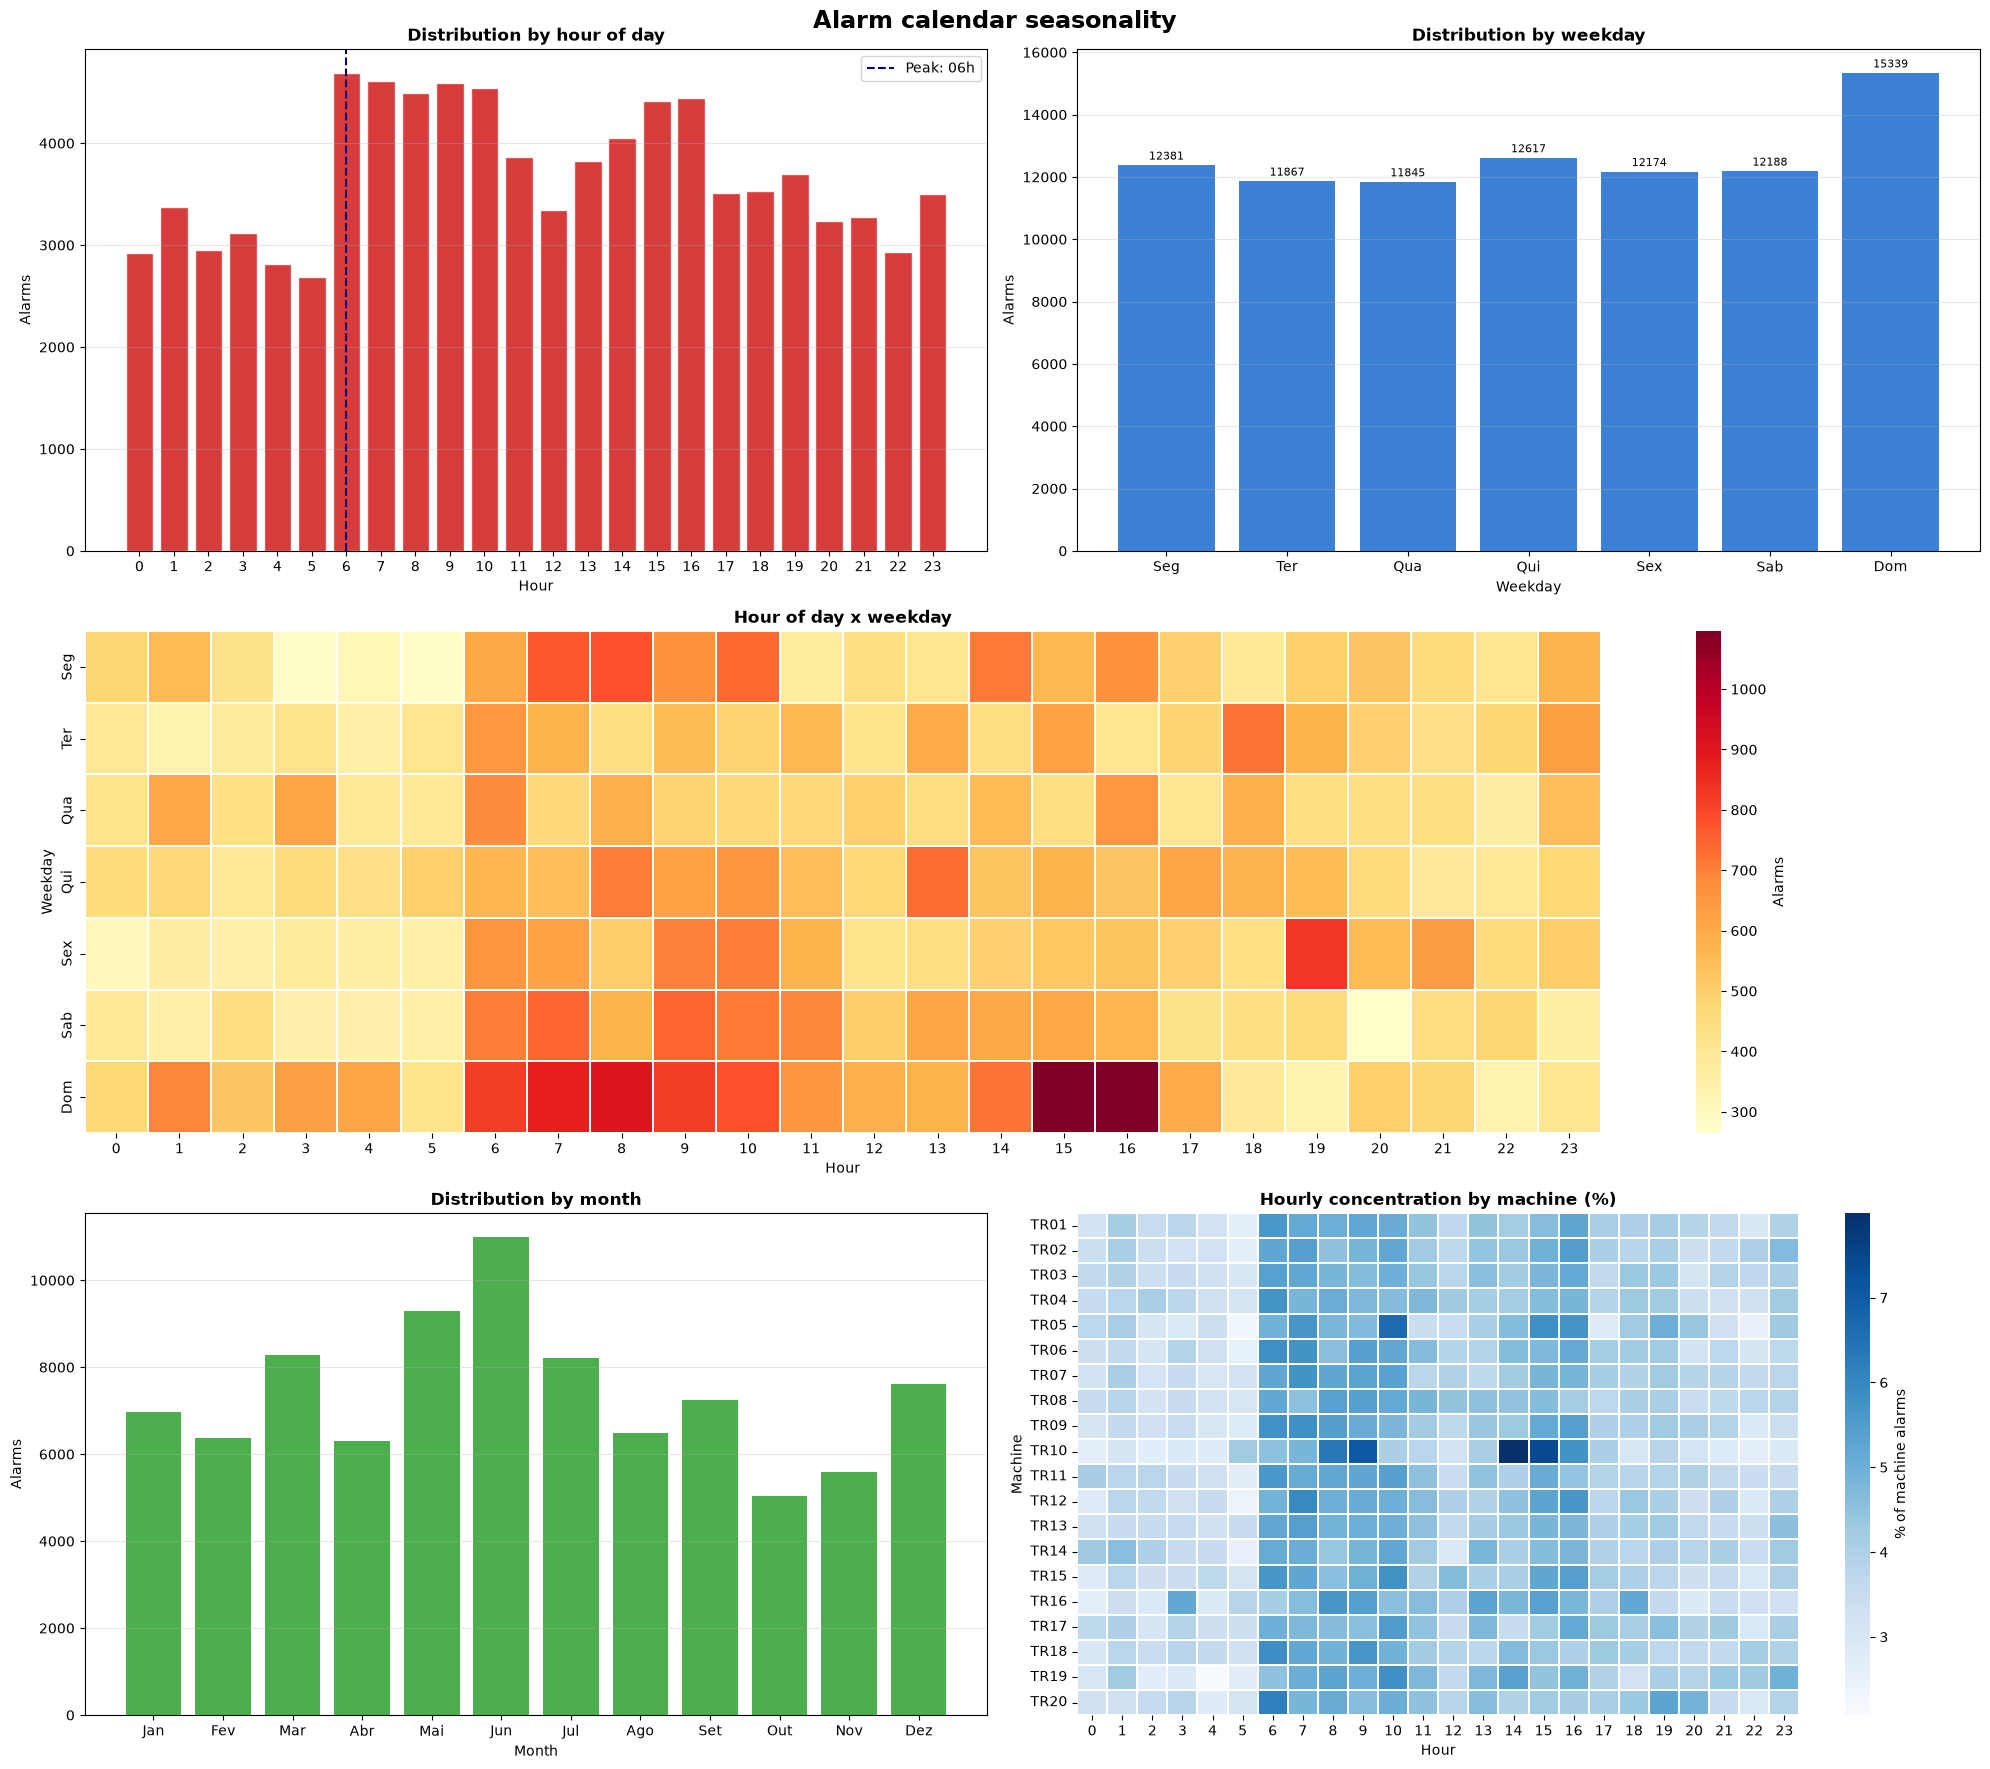

Peak_hour         6
Peak_weekday    Dom
Peak_month      Jun
Name: Peak period, dtype: object

In [16]:
calendar_seasonality_raw = analyze_calendar_seasonality(
    df_series_datetime,
    timestamp_col='timestamp',
    machine_col='maq',
    timezone='America/Recife',
)
calendar_tables_raw = calendar_seasonality_raw['tables']
calendar_peaks_raw = calendar_seasonality_raw['peaks']

_ = plot_calendar_seasonality(
    calendar_tables_raw,
    save_path='results/eda/seasonality/calendar_seasonality_raw.png',
)
display(pd.Series(calendar_peaks_raw, name='Peak period'))

[LOG] Plot saved to: results/eda/seasonality/conditional_patterns_raw.png


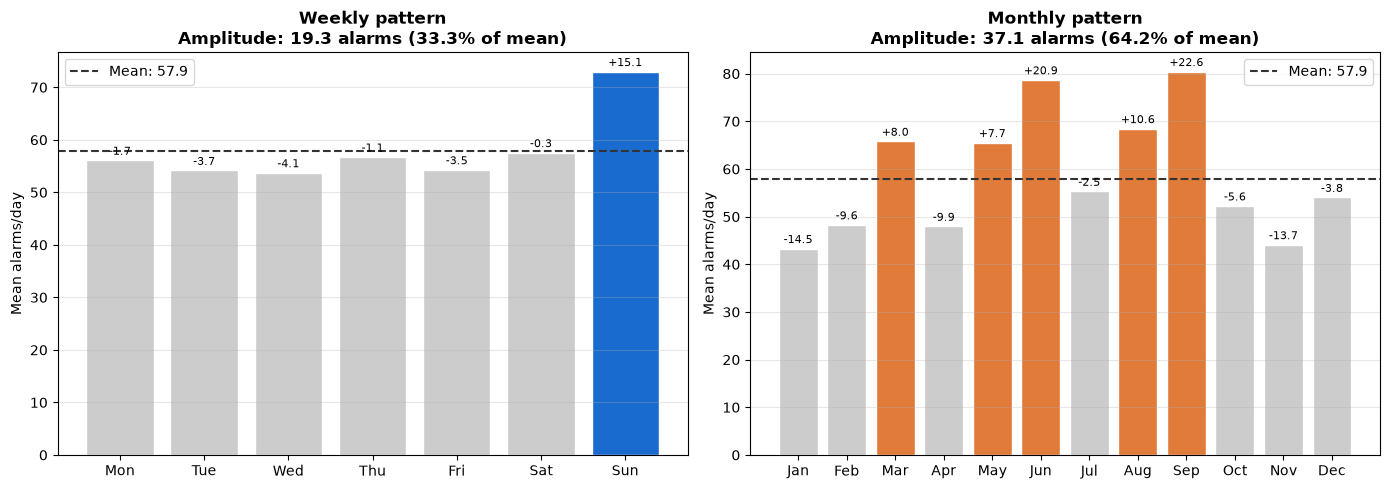

[LOG] Plot saved to: results/eda/seasonality/conditional_patterns_no_outliers.png


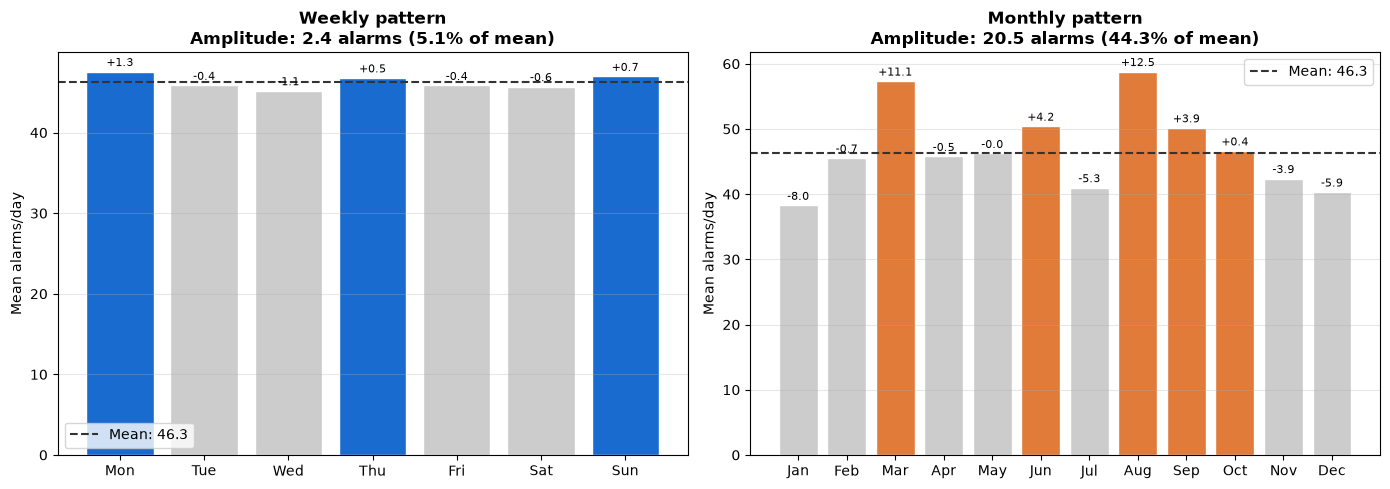

,Label,Mean_alarms,Deviation_from_mean,Series
0,Mon,56.12,-1.75,Raw
1,Tue,54.17,-3.69,Raw
2,Wed,53.74,-4.12,Raw
3,Thu,56.73,-1.13,Raw
4,Fri,54.31,-3.55,Raw
5,Sat,57.56,-0.30,Raw
6,Sun,73.00,15.14,Raw


,Label,Mean_alarms,Deviation_from_mean,Series
0,Mon,47.58,1.30,No outliers
1,Tue,45.87,-0.41,No outliers
2,Wed,45.20,-1.08,No outliers
3,Thu,46.80,0.52,No outliers
4,Fri,45.86,-0.42,No outliers
5,Sat,45.72,-0.56,No outliers
6,Sun,46.98,0.70,No outliers


In [17]:
weekly_pattern_raw, monthly_pattern_raw, _ = plot_conditional_patterns(
    daily_agg_time_series,
    save_path='results/eda/seasonality/conditional_patterns_raw.png',
)
weekly_pattern_clean, monthly_pattern_clean, _ = plot_conditional_patterns(
    daily_agg_ts_no_outliers,
    save_path='results/eda/seasonality/conditional_patterns_no_outliers.png',
)

display(weekly_pattern_raw.assign(Series='Raw'))
display(weekly_pattern_clean.assign(Series='No outliers'))

### 3.5 Zero-Alarm Gaps and Production Pauses

All gaps are retained for classification, while the summary and duration ranking apply the report's minimum relevance threshold of two days.

[LOG] Identified 48 gap(s) lasting at least 1 day(s)
[LOG] Gap categories: {'Unclassified': 35, 'Easter': 4, 'Plant stoppage': 3, 'Carnival': 3, 'Unresolved': 2, 'COVID-19': 1}


,Gaps,Total_days,Longest_gap
Category,,,
Unresolved,2,160,90
Unclassified,19,101,11
Plant stoppage,3,81,38
COVID-19,1,41,41
Carnival,3,13,5
Easter,4,13,4


,Start,End,Duration_days,Category,Label,Color,Requires_validation
0,2023-08-05 00:00:00+00:00,2023-11-02 00:00:00+00:00,90,Unresolved,Unresolved hiatus (90 days),#333333,True
1,2022-07-28 00:00:00+00:00,2022-10-05 00:00:00+00:00,70,Unresolved,Unresolved hiatus (70 days),#333333,True
2,2020-03-26 00:00:00+00:00,2020-05-05 00:00:00+00:00,41,COVID-19,COVID-19 shutdown,#8b0000,False
3,2023-03-03 00:00:00+00:00,2023-04-09 00:00:00+00:00,38,Plant stoppage,Plant stoppage,#e07b39,False
4,2021-01-23 00:00:00+00:00,2021-02-13 00:00:00+00:00,22,Plant stoppage,Plant stoppage,#e07b39,False
5,2021-02-26 00:00:00+00:00,2021-03-18 00:00:00+00:00,21,Plant stoppage,Plant stoppage,#e07b39,False
6,2020-10-30 00:00:00+00:00,2020-11-09 00:00:00+00:00,11,Unclassified,Unclassified,#999999,True
7,2022-05-09 00:00:00+00:00,2022-05-19 00:00:00+00:00,11,Unclassified,Unclassified,#999999,True
8,2020-10-02 00:00:00+00:00,2020-10-11 00:00:00+00:00,10,Unclassified,Unclassified,#999999,True
9,2021-10-10 00:00:00+00:00,2021-10-19 00:00:00+00:00,10,Unclassified,Unclassified,#999999,True


[LOG] Plot saved to: results/eda/gaps/gaps_overview_raw.png


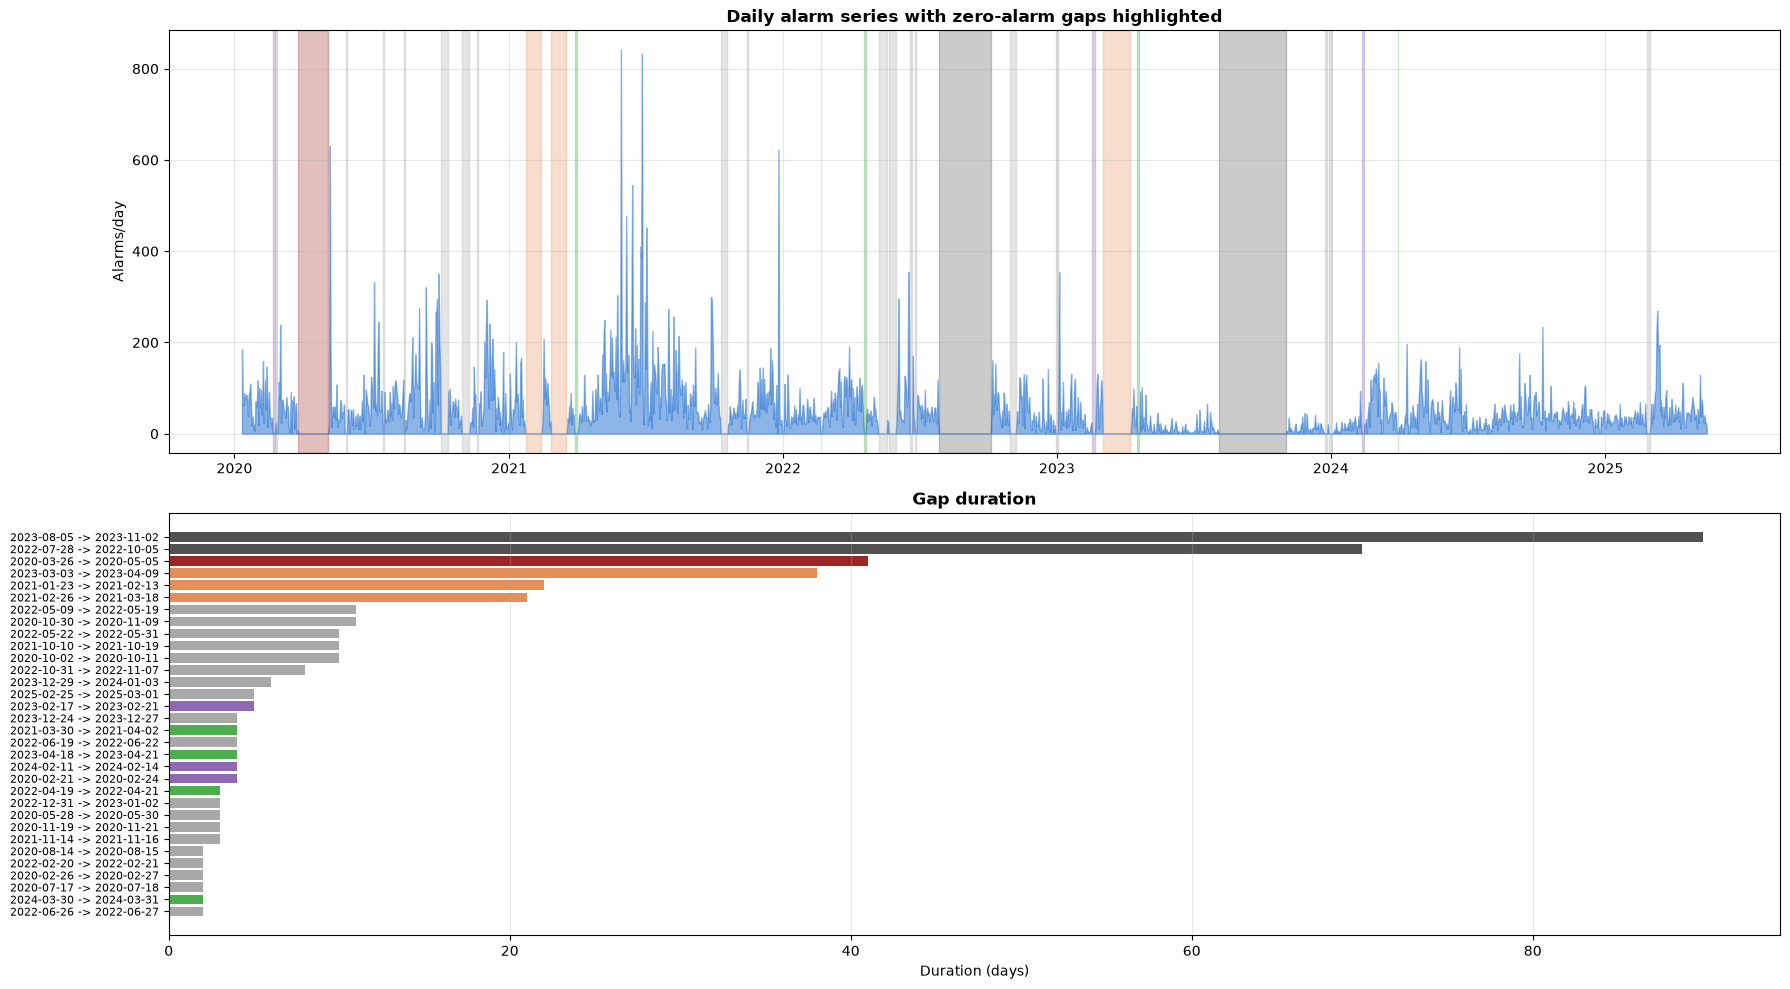

[LOG] Plot saved to: results/eda/gaps/classified_gap_series_raw.png


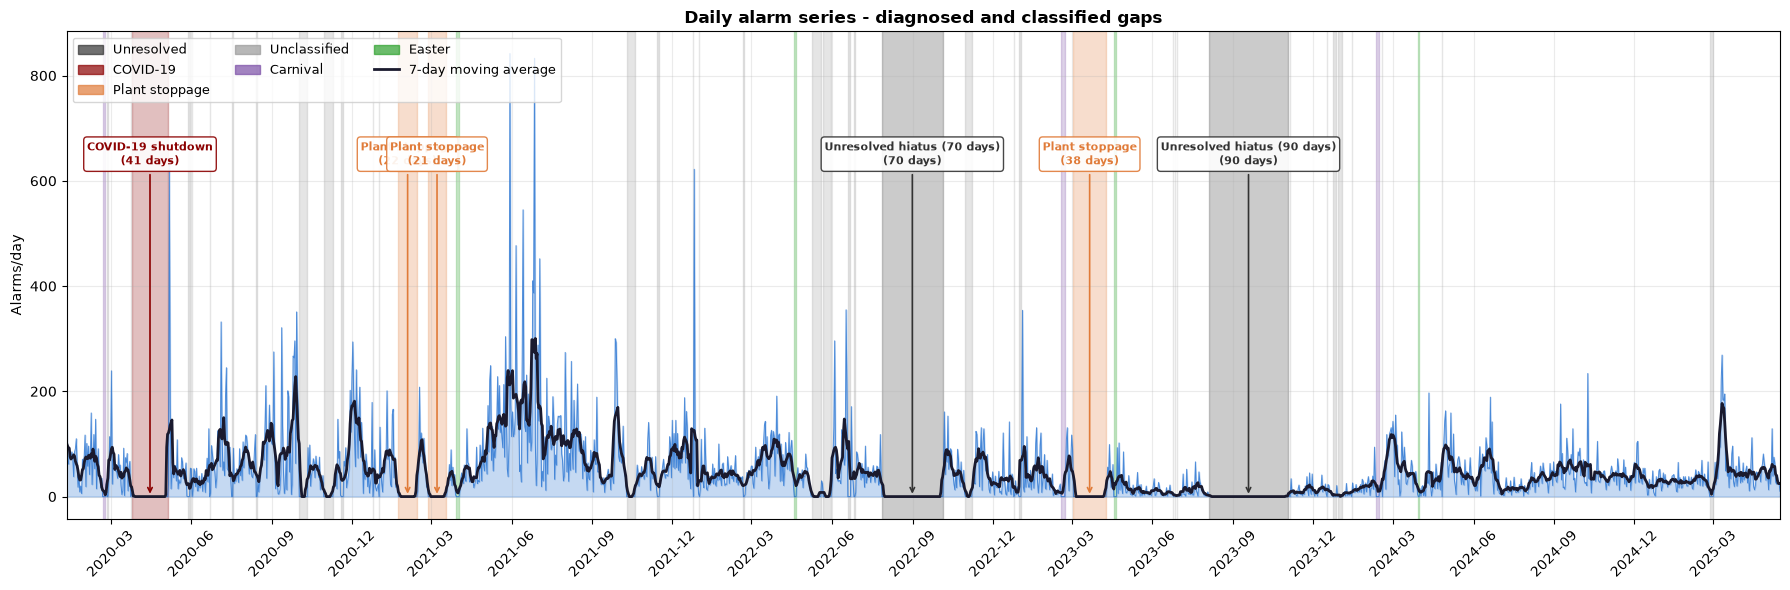

In [18]:
gaps_raw = identify_gaps(daily_agg_time_series, min_days=1)
gaps_classified_raw = classify_gaps(gaps_raw)
gaps_relevant_raw = gaps_classified_raw.loc[
    gaps_classified_raw['Duration_days'].ge(2)
].copy()
gap_summary_raw = gap_summary(gaps_relevant_raw)

display(gap_summary_raw)
display(gaps_relevant_raw.head(15))

_ = plot_gaps_overview(
    daily_agg_time_series,
    gaps_relevant_raw,
    save_path='results/eda/gaps/gaps_overview_raw.png',
)
_ = plot_classified_gap_series(
    daily_agg_time_series,
    gaps_classified_raw,
    save_path='results/eda/gaps/classified_gap_series_raw.png',
)

### 3.6 Inter-Alarm Time and Recurrence by Machine and Shift

Inter-alarm time is computed once from the raw row-level time series. The same prepared dataset is then reused by all recurrence tables and plots.

In [19]:
recurrence_analysis_raw = build_recurrence_analysis(
    df_series_datetime,
    group_col='maq',
    timestamp_col='timestamp',
    thresholds=(15, 30, 60),
    shift_col='shift',
    timezone='America/Recife',
)

alarm_iat_raw = recurrence_analysis_raw['data']
recurrence_rates_raw = recurrence_analysis_raw['rates']
recurrence_by_shift_raw = recurrence_analysis_raw['by_shift']

[LOG] Inter-alarm time 'IAT_min' computed for 20 group(s): 88,391 valid interval(s), 0 non-positive interval(s) ignored
[LOG] Shifts assigned: {'1T (06h-14h)': 33957, '2T (14h-22h)': 30159, '3T (22h-06h)': 24295}
[LOG] Recurrence rates computed for 20 group(s) at thresholds [15, 30, 60] min
[LOG] Recurrence by shift computed at 15 min: 20 group(s) x 3 shift(s)
[LOG] Recurrence by shift computed at 30 min: 20 group(s) x 3 shift(s)
[LOG] Recurrence by shift computed at 60 min: 20 group(s) x 3 shift(s)


[LOG] Inter-alarm statistics computed for 20 group(s)
[LOG] Inter-alarm median pivot built: 20 group(s) x 6 year(s)
[LOG] Plot saved to: results/eda/interalarm/inter_alarm_overview_raw.png


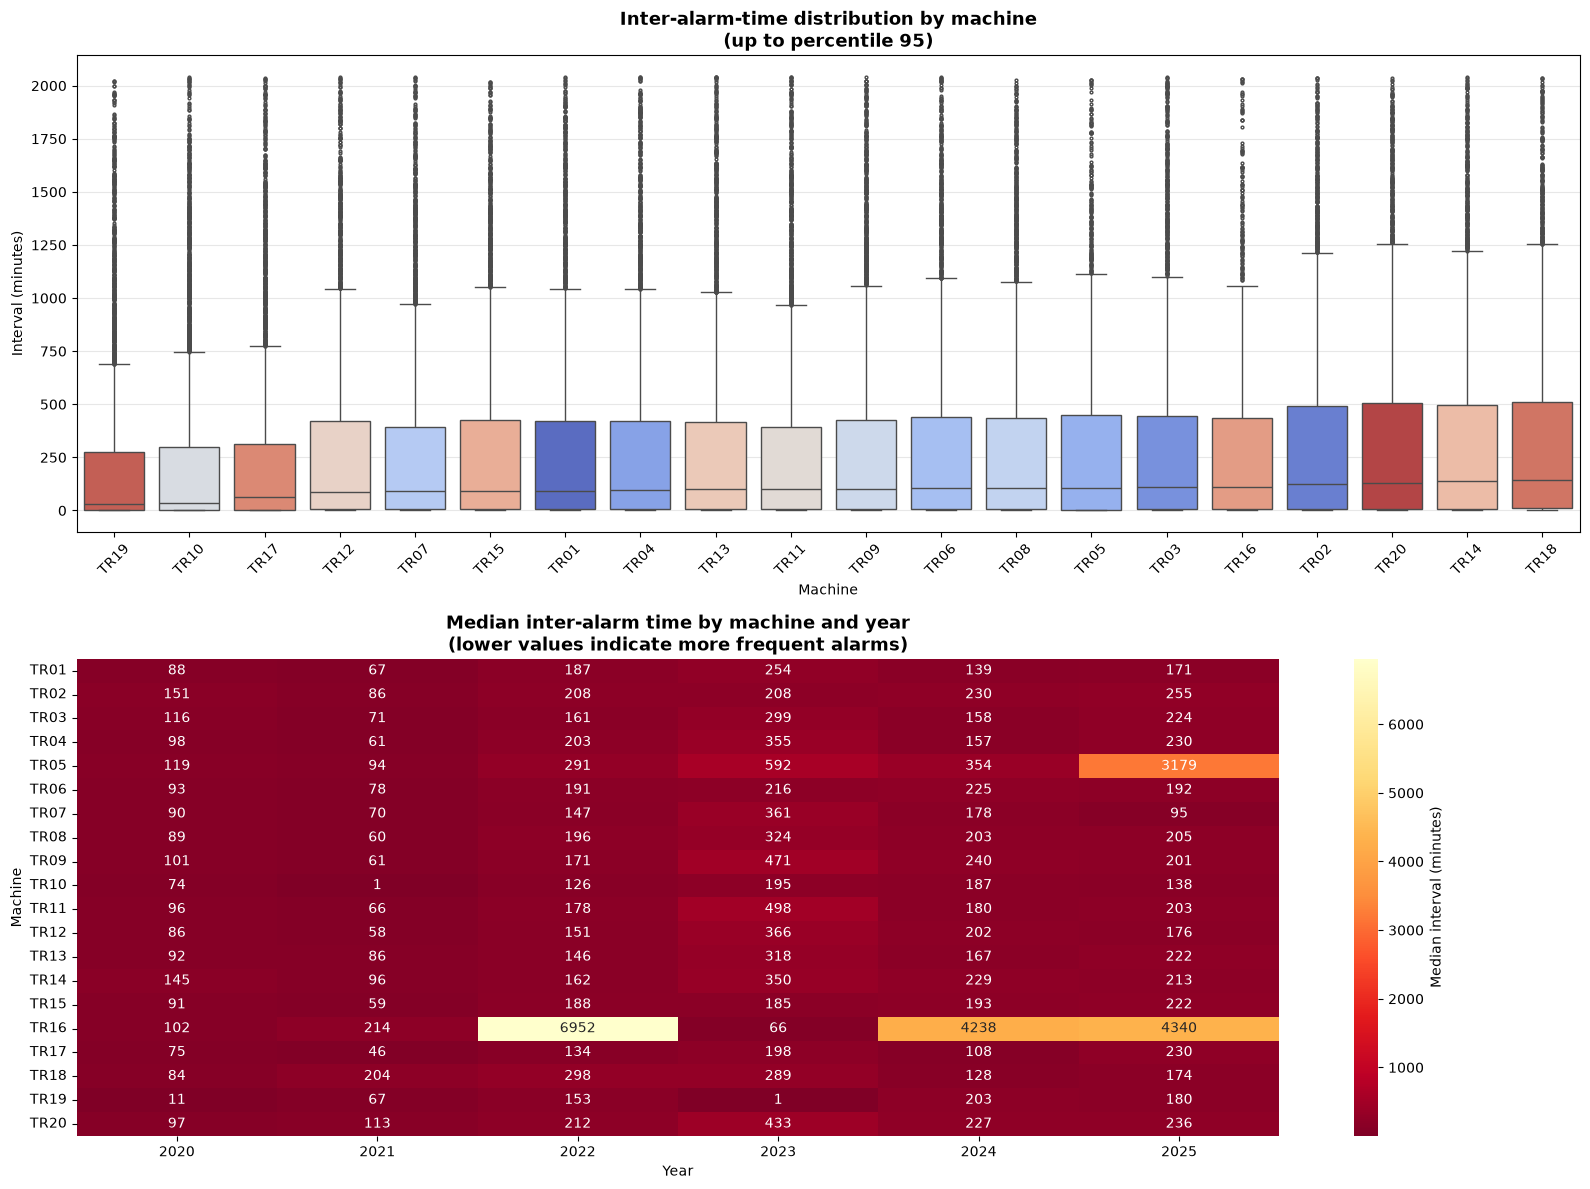

,Median,Mean,Std,Minimum,Maximum,N
maq,,,,,,
TR19,38.71,566.97,5762.00,0.00,353277.38,4956
TR10,43.77,440.72,2836.61,0.00,136980.30,6378
TR17,73.08,508.12,2986.93,0.00,138075.16,5526
TR12,106.35,607.07,4189.11,0.00,215476.92,4628
TR07,108.97,597.06,3366.73,0.00,136980.29,4689
TR15,112.15,623.91,4499.54,0.00,237515.01,4505
TR01,112.95,555.86,2966.97,0.00,136980.29,5055
TR11,115.59,562.31,3271.31,0.00,137129.90,4996
TR04,118.68,581.94,3161.24,0.00,138476.46,4809


In [20]:
iat_statistics_raw = inter_alarm_statistics(
    alarm_iat_raw,
    group_col='maq',
    iat_col='IAT_min',
)
iat_boxplot_raw, iat_by_year_raw, _ = plot_inter_alarm_overview(
    alarm_iat_raw,
    group_col='maq',
    timestamp_col='timestamp',
    iat_col='IAT_min',
    save_path='results/eda/interalarm/inter_alarm_overview_raw.png',
)

display(iat_statistics_raw)

[LOG] Plot saved to: results/eda/recurrence/recurrence_rate_30min_raw.png


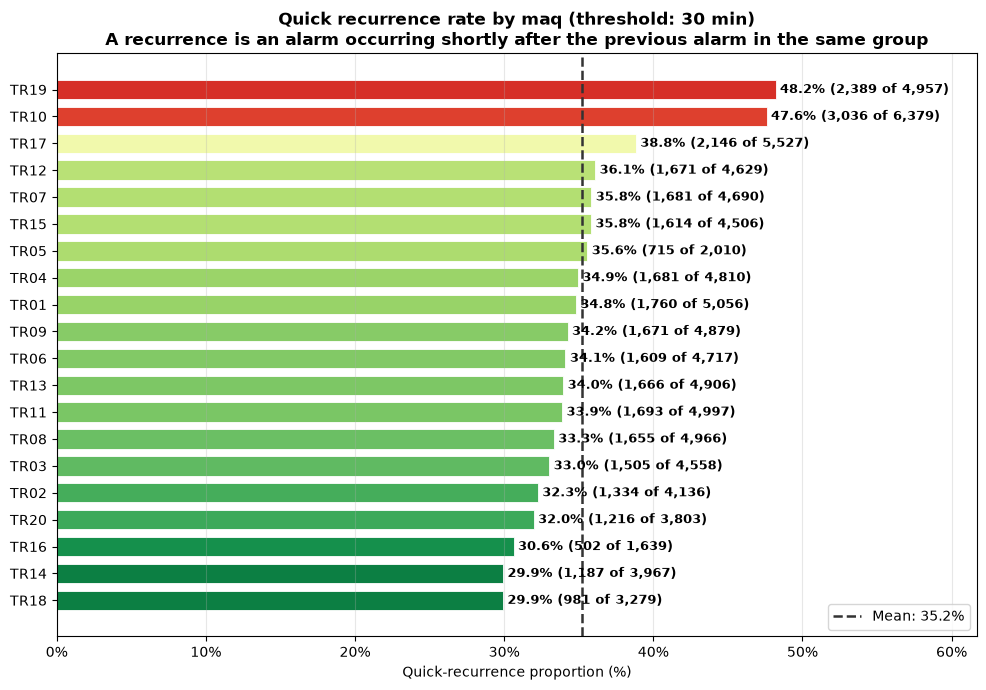

[LOG] Plot saved to: results/eda/recurrence/recurrence_thresholds_raw.png


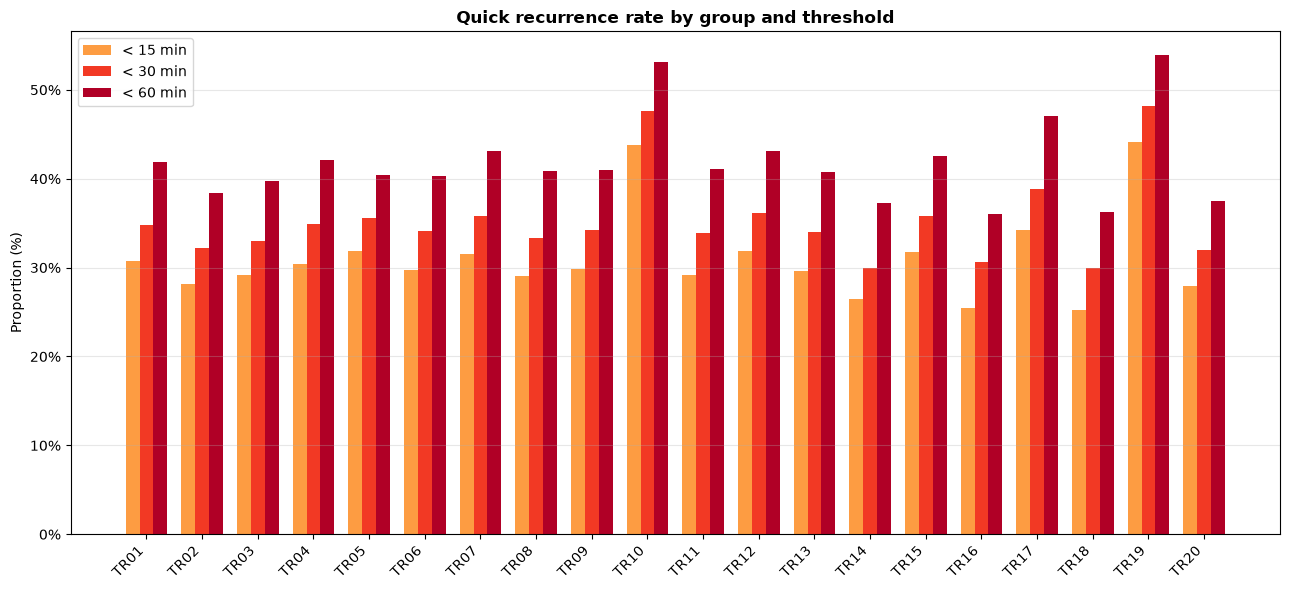

[LOG] Plot saved to: results/eda/recurrence/recurrence_by_shift_30min_raw.png


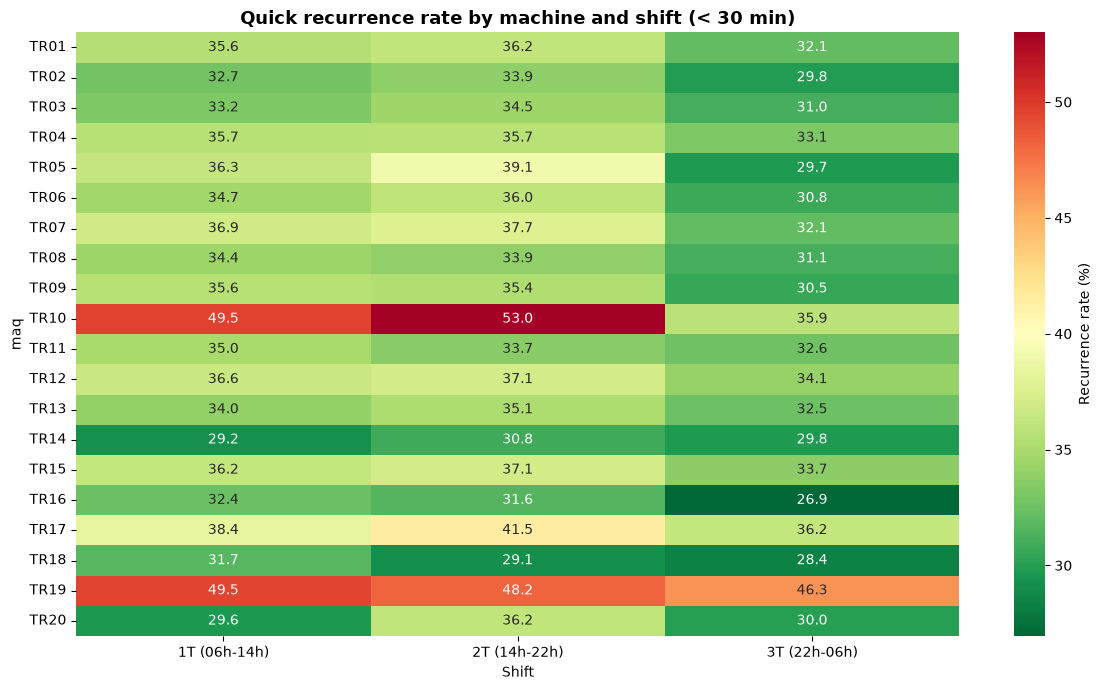

,maq,Threshold_min,Recurrences,Total,Proportion
55,TR19,30,2389,4957,48.19
28,TR10,30,3036,6379,47.59
49,TR17,30,2146,5527,38.83
34,TR12,30,1671,4629,36.10
19,TR07,30,1681,4690,35.84
43,TR15,30,1614,4506,35.82
13,TR05,30,715,2010,35.57
10,TR04,30,1681,4810,34.95
1,TR01,30,1760,5056,34.81
25,TR09,30,1671,4879,34.25


In [21]:
recurrence_30min_raw = plot_recurrence_rate(
    recurrence_rates_raw,
    group_col='maq',
    threshold_min=30,
    save_path='results/eda/recurrence/recurrence_rate_30min_raw.png',
)
_ = plot_recurrence_thresholds(
    recurrence_rates_raw,
    group_col='maq',
    thresholds=(15, 30, 60),
    save_path='results/eda/recurrence/recurrence_thresholds_raw.png',
)
_ = plot_recurrence_by_shift(
    recurrence_by_shift_raw[30],
    threshold_min=30,
    save_path='results/eda/recurrence/recurrence_by_shift_30min_raw.png',
)

display(recurrence_30min_raw)

### 3.7 FFT Spectral Analysis

The FFT is estimated separately for the raw and outlier-free daily series. Zero-alarm hiatuses are interpolated internally only for spectral estimation; the source series remain unchanged.

[LOG] Spectral series prepared: 1,953 observations, interpolate_zero_days=True
[LOG] FFT spectrum computed: 976 positive frequency bins
[LOG] Spectral power summarized by frequency band
[LOG] Plot saved to: results/eda/spectral/fft_power_spectrum_raw.png


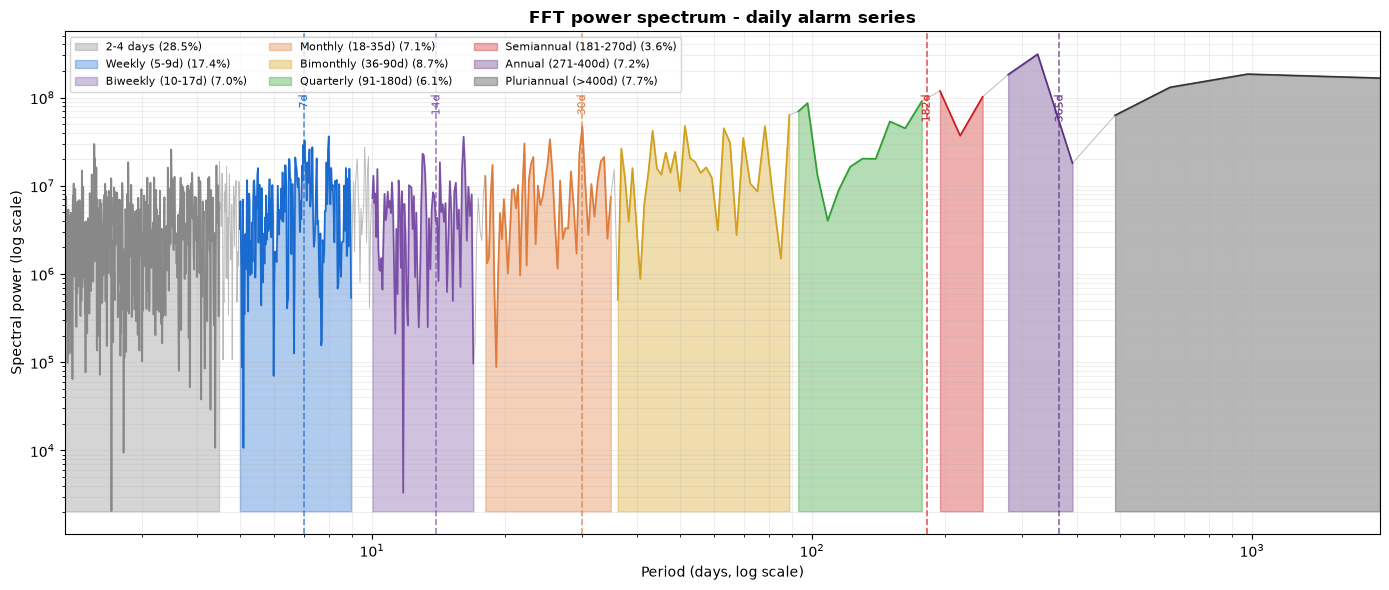

,Band,Min_period_days,Max_period_days,Power_pct,Peak_period_days
0,2-4 days,2,4.50,28.50,2.34
1,Weekly (5-9d),5,9.00,17.38,7.97
2,Biweekly (10-17d),10,17.00,7.05,16.14
3,Monthly (18-35d),18,35.00,7.06,30.05
4,Bimonthly (36-90d),36,90.00,8.65,88.77
5,Quarterly (91-180d),91,180.00,6.07,177.55
6,Semiannual (181-270d),181,270.00,3.65,195.30
7,Annual (271-400d),271,400.00,7.22,325.50
8,Pluriannual (>400d),400,inf,7.70,976.50


In [22]:
fft_spectrum_raw, fft_interpolated_raw, fft_detrended_raw = compute_fft_spectrum(
    daily_agg_time_series,
    interpolate_zero_days=True,
)
fft_bands_raw = summarize_frequency_bands(fft_spectrum_raw)
_ = plot_power_spectrum(
    fft_spectrum_raw,
    band_summary=fft_bands_raw,
    save_path='results/eda/spectral/fft_power_spectrum_raw.png',
)

display(fft_bands_raw.drop(columns='Color'))

[LOG] Spectral series prepared: 1,953 observations, interpolate_zero_days=True
[LOG] FFT spectrum computed: 976 positive frequency bins
[LOG] Spectral power summarized by frequency band
[LOG] Plot saved to: results/eda/spectral/fft_power_spectrum_no_outliers.png


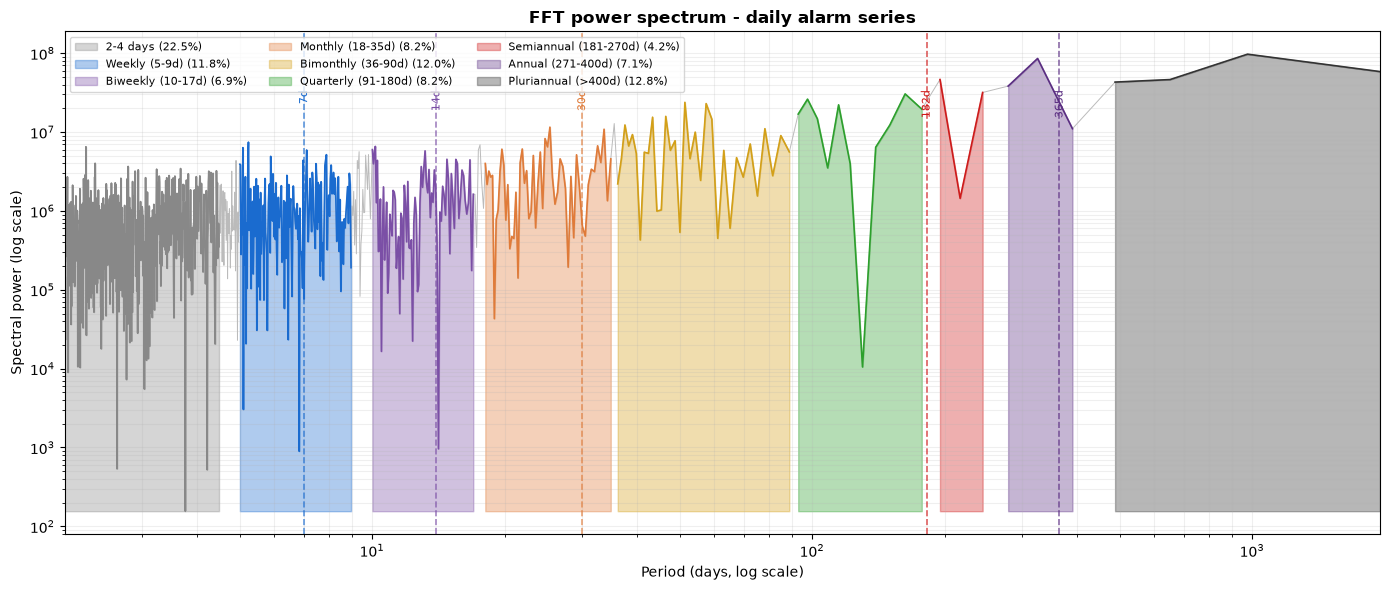

,Band,Min_period_days,Max_period_days,Power_pct,Peak_period_days
0,2-4 days,2,4.50,22.55,2.24
1,Weekly (5-9d),5,9.00,11.78,5.24
2,Biweekly (10-17d),10,17.00,6.95,10.17
3,Monthly (18-35d),18,35.00,8.24,25.36
4,Bimonthly (36-90d),36,90.00,11.96,51.39
5,Quarterly (91-180d),91,180.00,8.16,162.75
6,Semiannual (181-270d),181,270.00,4.16,195.30
7,Annual (271-400d),271,400.00,7.06,325.50
8,Pluriannual (>400d),400,inf,12.80,976.50


In [23]:
fft_spectrum_clean, fft_interpolated_clean, fft_detrended_clean = compute_fft_spectrum(
    daily_agg_ts_no_outliers,
    interpolate_zero_days=True,
)
fft_bands_clean = summarize_frequency_bands(fft_spectrum_clean)
_ = plot_power_spectrum(
    fft_spectrum_clean,
    band_summary=fft_bands_clean,
    save_path='results/eda/spectral/fft_power_spectrum_no_outliers.png',
)

display(fft_bands_clean.drop(columns='Color'))

### 3.8 Additive Decomposition

Trend, weekly seasonality, monthly seasonality, and residuals are computed independently for the raw and outlier-free daily series.

[LOG] Additive decomposition computed: trend_window=30, maximum reconstruction error=2.842e-14
[LOG] Plot saved to: results/eda/decomposition/additive_decomposition_raw.png


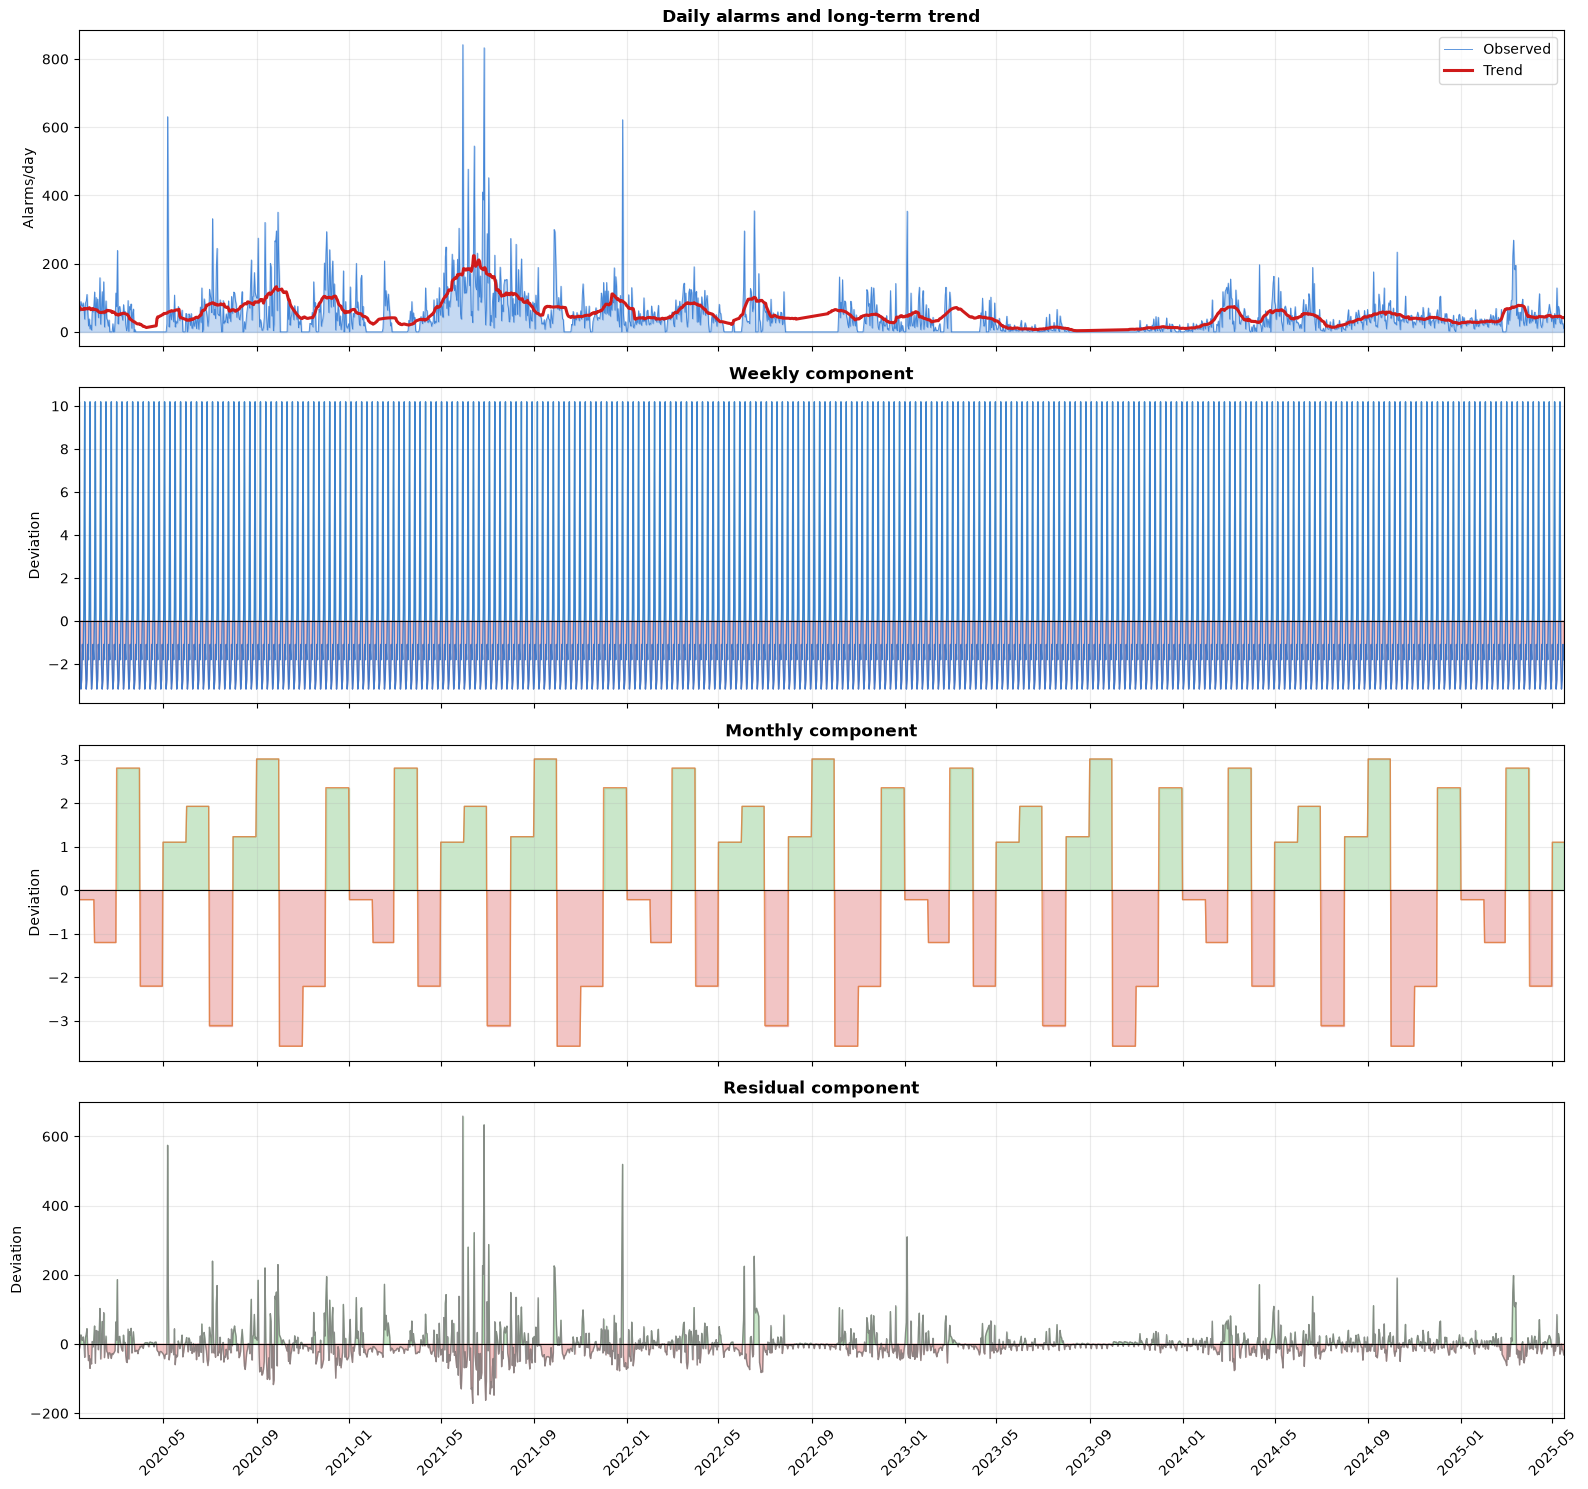

Trend_range         219.83
Weekly_amplitude     13.36
Monthly_amplitude     6.60
Residual_std         50.67
Name: Value, dtype: float64

In [24]:
additive_decomposition_raw = compute_additive_decomposition(
    daily_agg_time_series,
    trend_window=30,
    interpolate_zero_days=True,
)
additive_summary_raw = decomposition_summary(additive_decomposition_raw)
_ = plot_additive_decomposition(
    additive_decomposition_raw,
    save_path='results/eda/decomposition/additive_decomposition_raw.png',
)

display(additive_summary_raw)

In [25]:
additive_decomposition_clean = compute_additive_decomposition(
    daily_agg_ts_no_outliers,
    trend_window=30,
    interpolate_zero_days=True,
)
additive_summary_clean = decomposition_summary(additive_decomposition_clean)
_ = plot_additive_decomposition(
    additive_decomposition_clean,
    save_path='results/eda/decomposition/additive_decomposition_no_outliers.png',
)

display(additive_summary_clean)

[LOG] Additive decomposition computed: trend_window=30, maximum reconstruction error=1.421e-14
[LOG] Plot saved to: results/eda/decomposition/additive_decomposition_no_outliers.png


Trend_range         100.21
Weekly_amplitude      1.50
Monthly_amplitude     3.92
Residual_std         24.72
Name: Value, dtype: float64

## 4. Correlation Analysis

### 4.1 Endogenous Variables (Fault Codes)

[LOG] Counts by 'fault_code1':
fault_code1
0     78155
1       165
2         4
4      2193
8         1
32     6975
64      918
dtype: int64

[LOG] Counts by 'fault_code2':
fault_code2
0    85134
1     3277
dtype: int64

[LOG] Counts by 'fault_code3':
fault_code3
0        45888
32       10462
128      18288
192       3517
256          2
448        163
512          4
1024       885
1152      1306
1216         2
2048         1
8192      6975
16384      555
16512      363
dtype: int64

[LOG] Correlation matrix:
             fault_code1  fault_code2  fault_code3
fault_code1         1.00        -0.06         1.00
fault_code2        -0.06         1.00        -0.06
fault_code3         1.00        -0.06         1.00
[LOG] Plot saved to: results/eda/correlations/fault_code_correlation.png


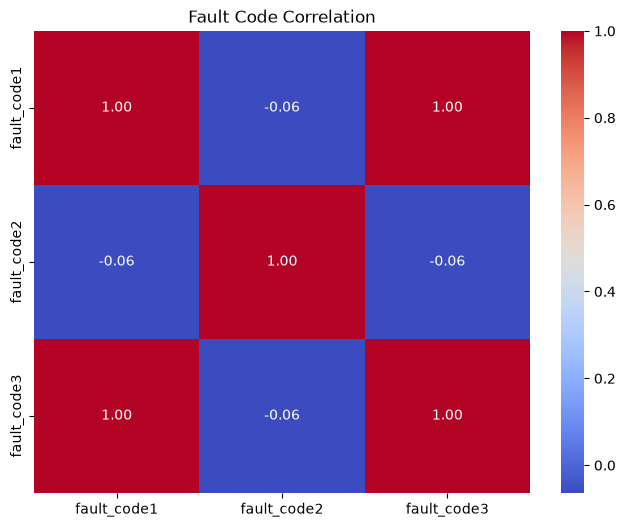

[LOG] fault_code1 == fault_code2: 74878 of 88411 rows (84.69%)
[LOG] fault_code1 == fault_code3: 45888 of 88411 rows (51.90%)
[LOG] fault_code2 == fault_code3: 42611 of 88411 rows (48.20%)
[LOG] Counts by 'fault_code1':
fault_code1
0     78155
1       165
2         4
4      2193
8         1
32     6975
64      918
dtype: int64

[LOG] Counts by 'fault_code2':
fault_code2
0    85134
1     3277
dtype: int64

[LOG] Correlation matrix:
             fault_code1  fault_code2
fault_code1         1.00        -0.06
fault_code2        -0.06         1.00
[LOG] fault_code1 == fault_code2: 74878 of 88411 rows (84.69%)
[LOG] Plot saved to: results/eda/correlations/fault_code1_vs_fault_code2.png


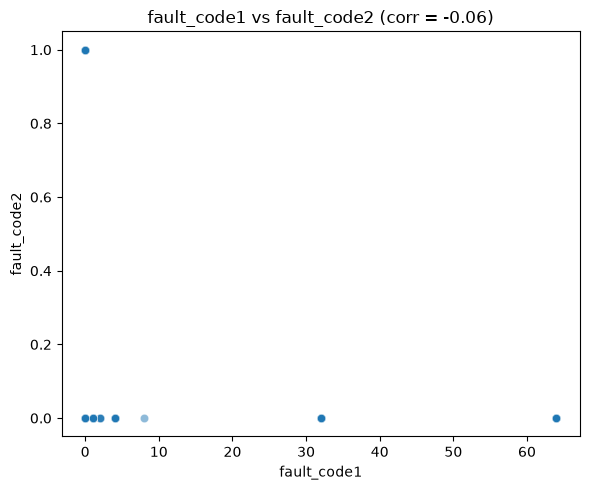

In [26]:
fault_code_correlation = n_cols_correlation(
    df_series_datetime,
    cols=['fault_code1', 'fault_code2', 'fault_code3'],
    title='Fault Code Correlation',
    save_path='results/eda/correlations/fault_code_correlation.png',
)
fault_code1_vs_fault_code2 = x_y_correlation(
    df_series_datetime,
    x='fault_code1',
    y='fault_code2',
    save_path='results/eda/correlations/fault_code1_vs_fault_code2.png',
)

### 4.2 Autocorrelation (ACF)

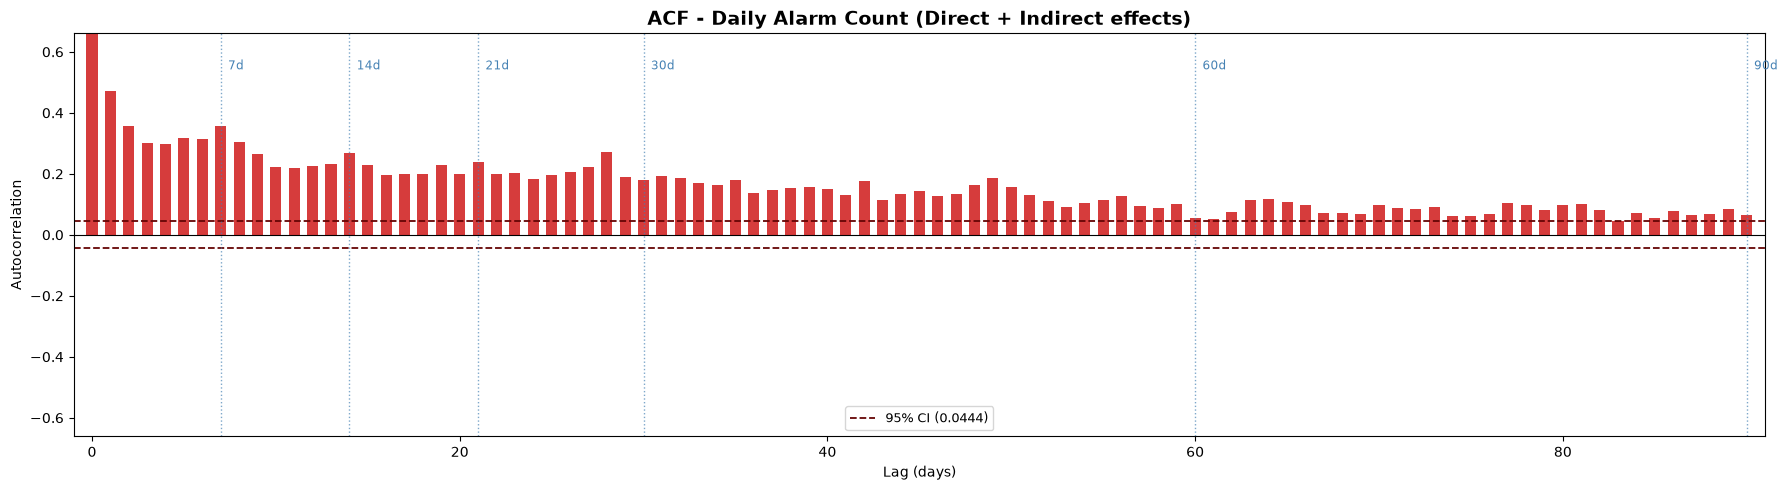

[LOG] ACF significant lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90]


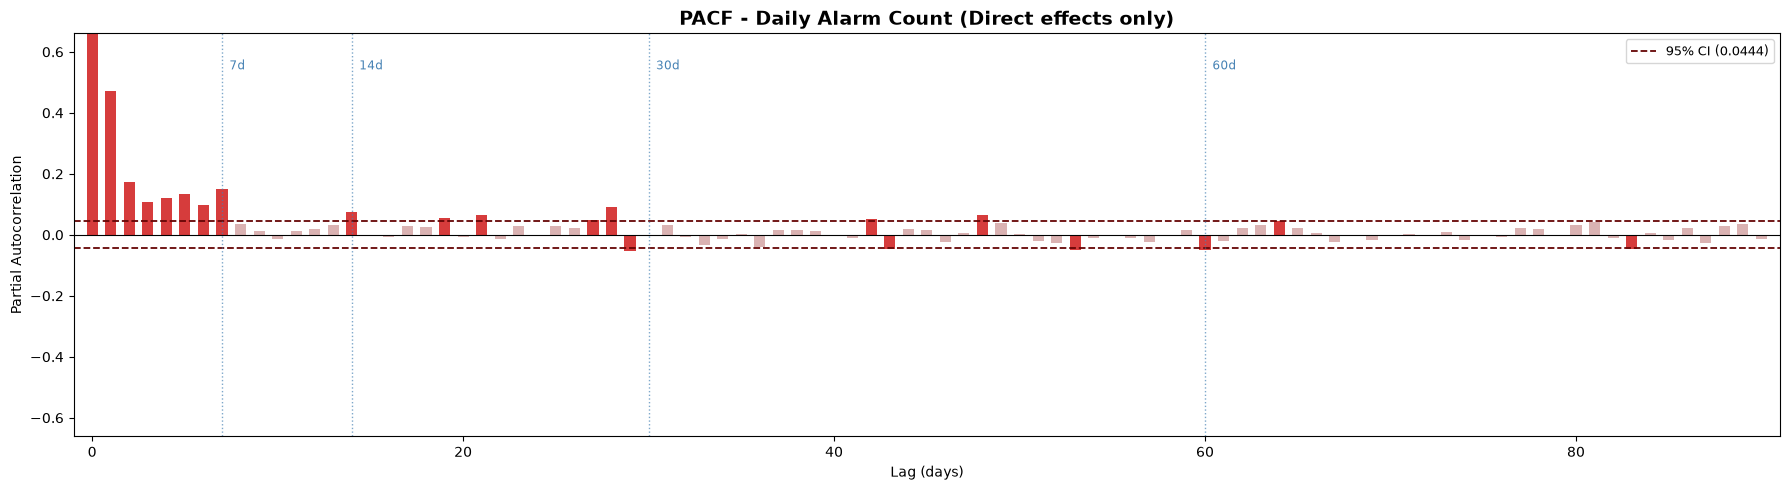

[LOG] PACF significant lags: [1, 2, 3, 4, 5, 6, 7, 14, 19, 21, 27, 28, 29, 42, 43, 48, 53, 60, 64, 83]
[LOG] Suggested AR order: 83


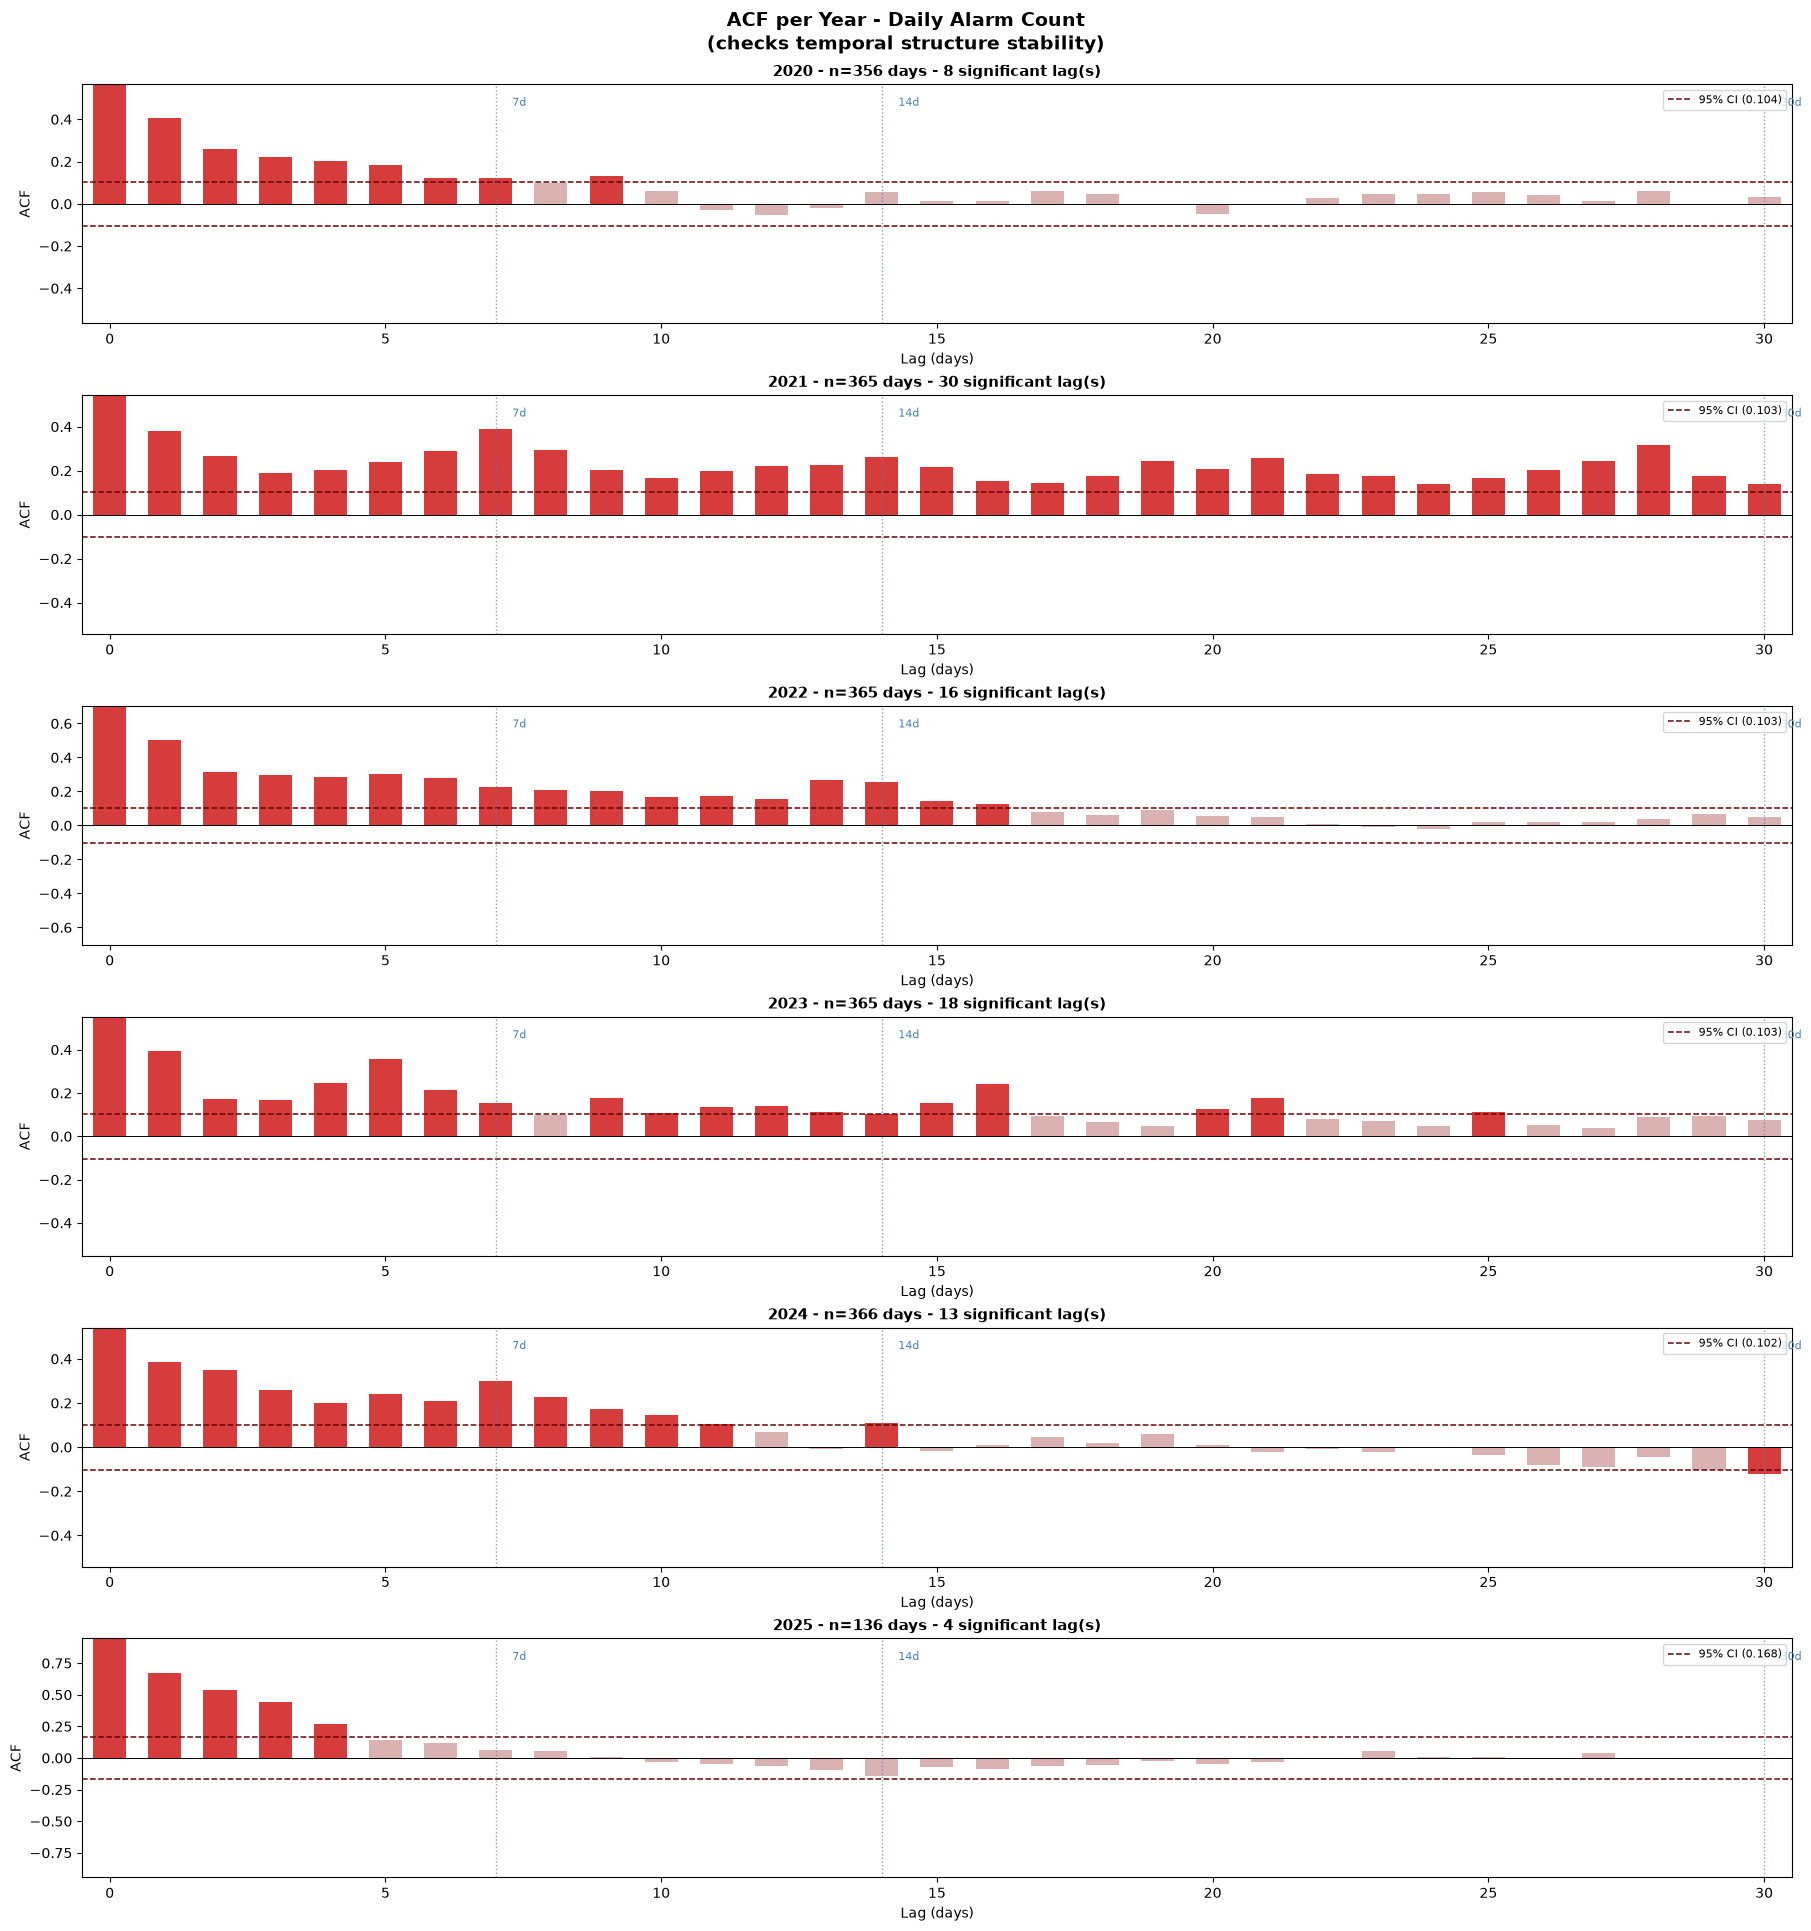

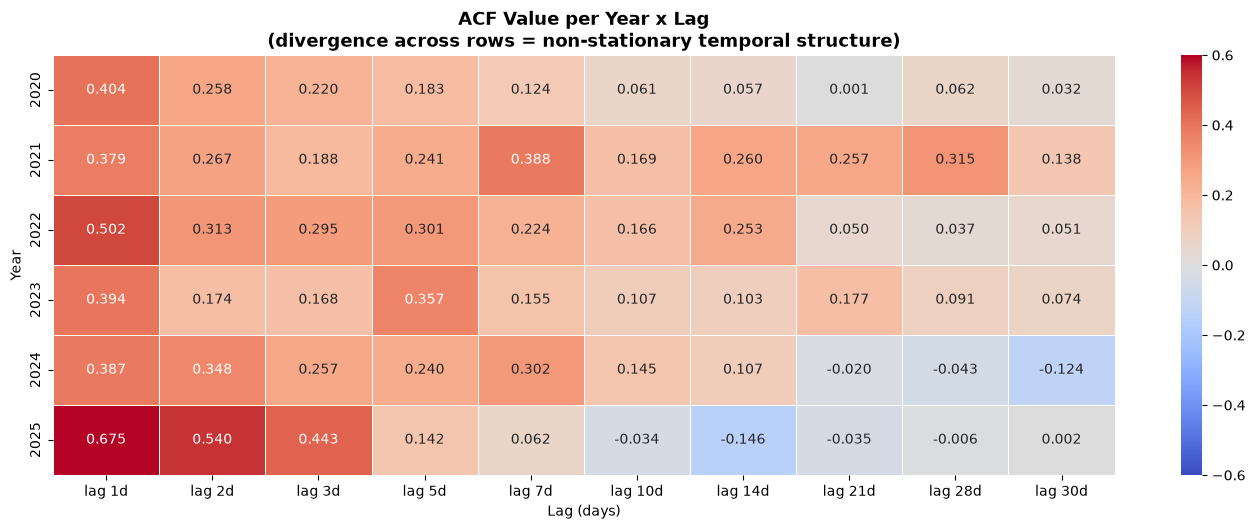

[LOG] ACF @ key lags per year:
      lag 1d  lag 2d  lag 3d  lag 5d  lag 7d  lag 10d  lag 14d  lag 21d  lag 28d  lag 30d
2020    0.40    0.26    0.22    0.18    0.12     0.06     0.06     0.00     0.06     0.03
2021    0.38    0.27    0.19    0.24    0.39     0.17     0.26     0.26     0.31     0.14
2022    0.50    0.31    0.29    0.30    0.22     0.17     0.25     0.05     0.04     0.05
2023    0.39    0.17    0.17    0.36    0.16     0.11     0.10     0.18     0.09     0.07
2024    0.39    0.35    0.26    0.24    0.30     0.14     0.11    -0.02    -0.04    -0.12
2025    0.68    0.54    0.44    0.14    0.06    -0.03    -0.15    -0.03    -0.01     0.00


In [27]:
acf_raw, pacf_raw = plot_acf_pacf(
    daily_agg_time_series,
    max_lags=90,
    save_dir='results/eda/correlations/acf/raw',
)
acf_year_heatmap_raw, acf_by_year_raw = acf_by_year_heatmap(
    daily_agg_time_series,
    save_dir='results/eda/correlations/acf/raw',
)

#### 4.2.1 Outlier-Free Daily Series

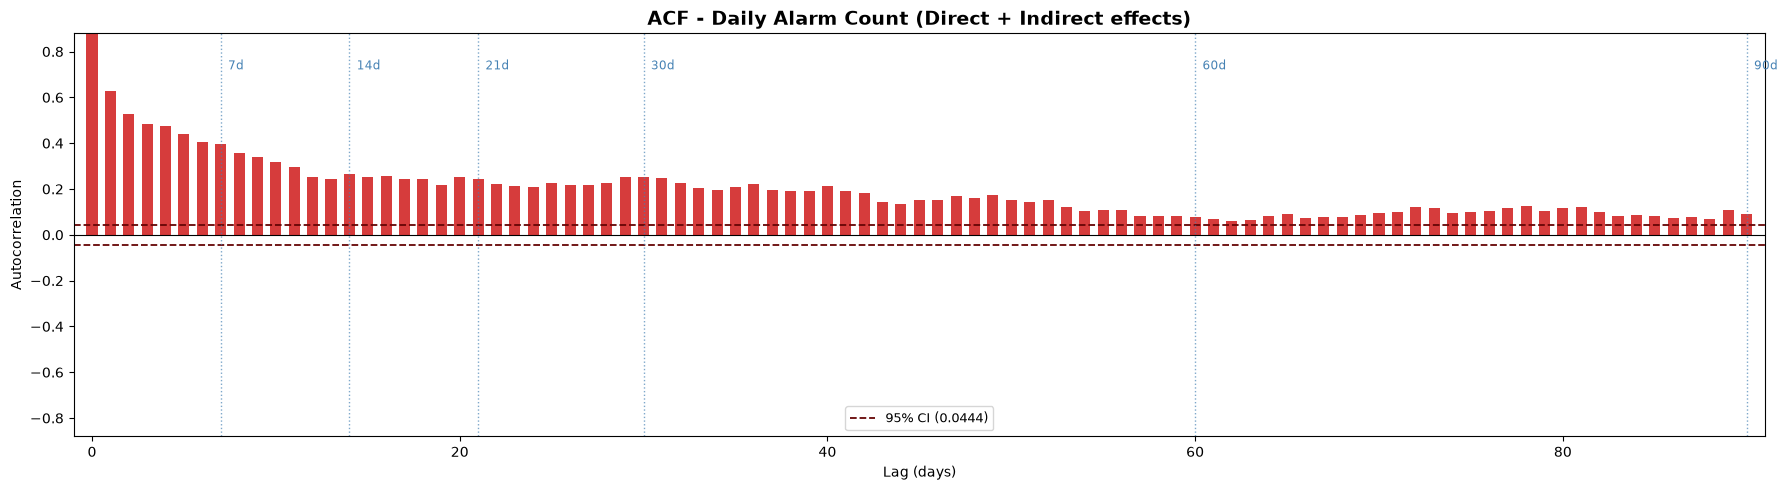

[LOG] ACF significant lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90]


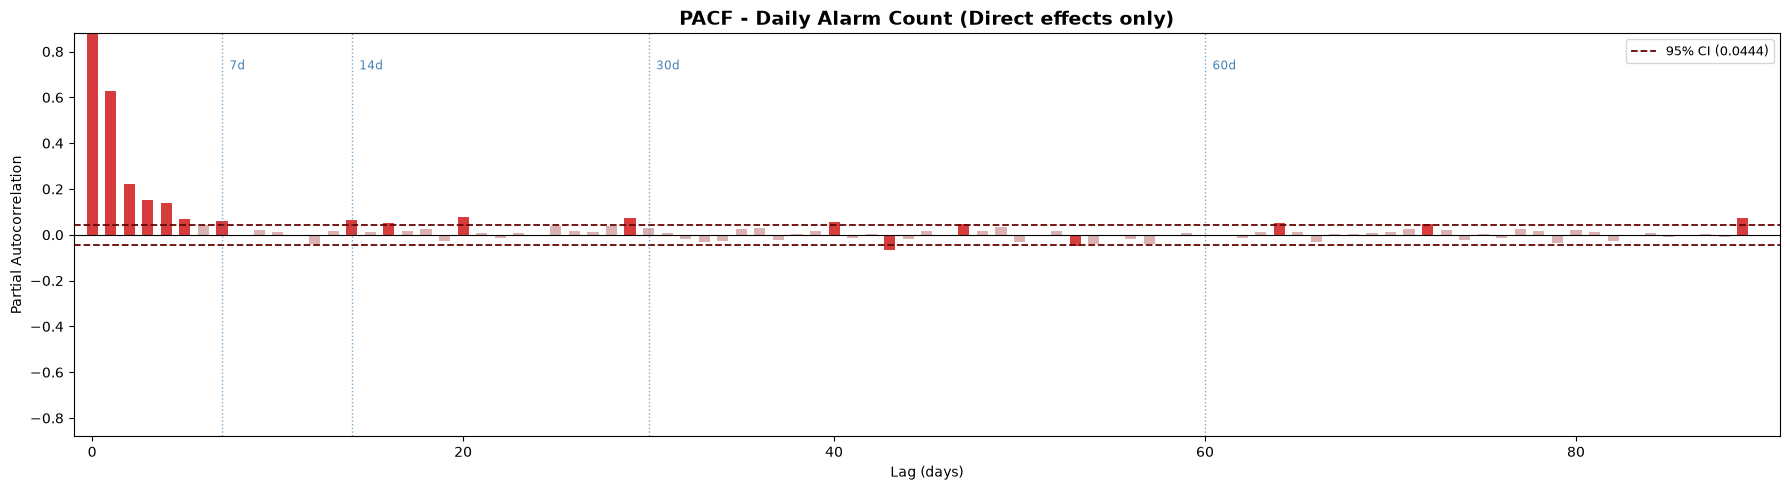

[LOG] PACF significant lags: [1, 2, 3, 4, 5, 7, 14, 16, 20, 29, 40, 43, 47, 53, 64, 72, 89]
[LOG] Suggested AR order: 89


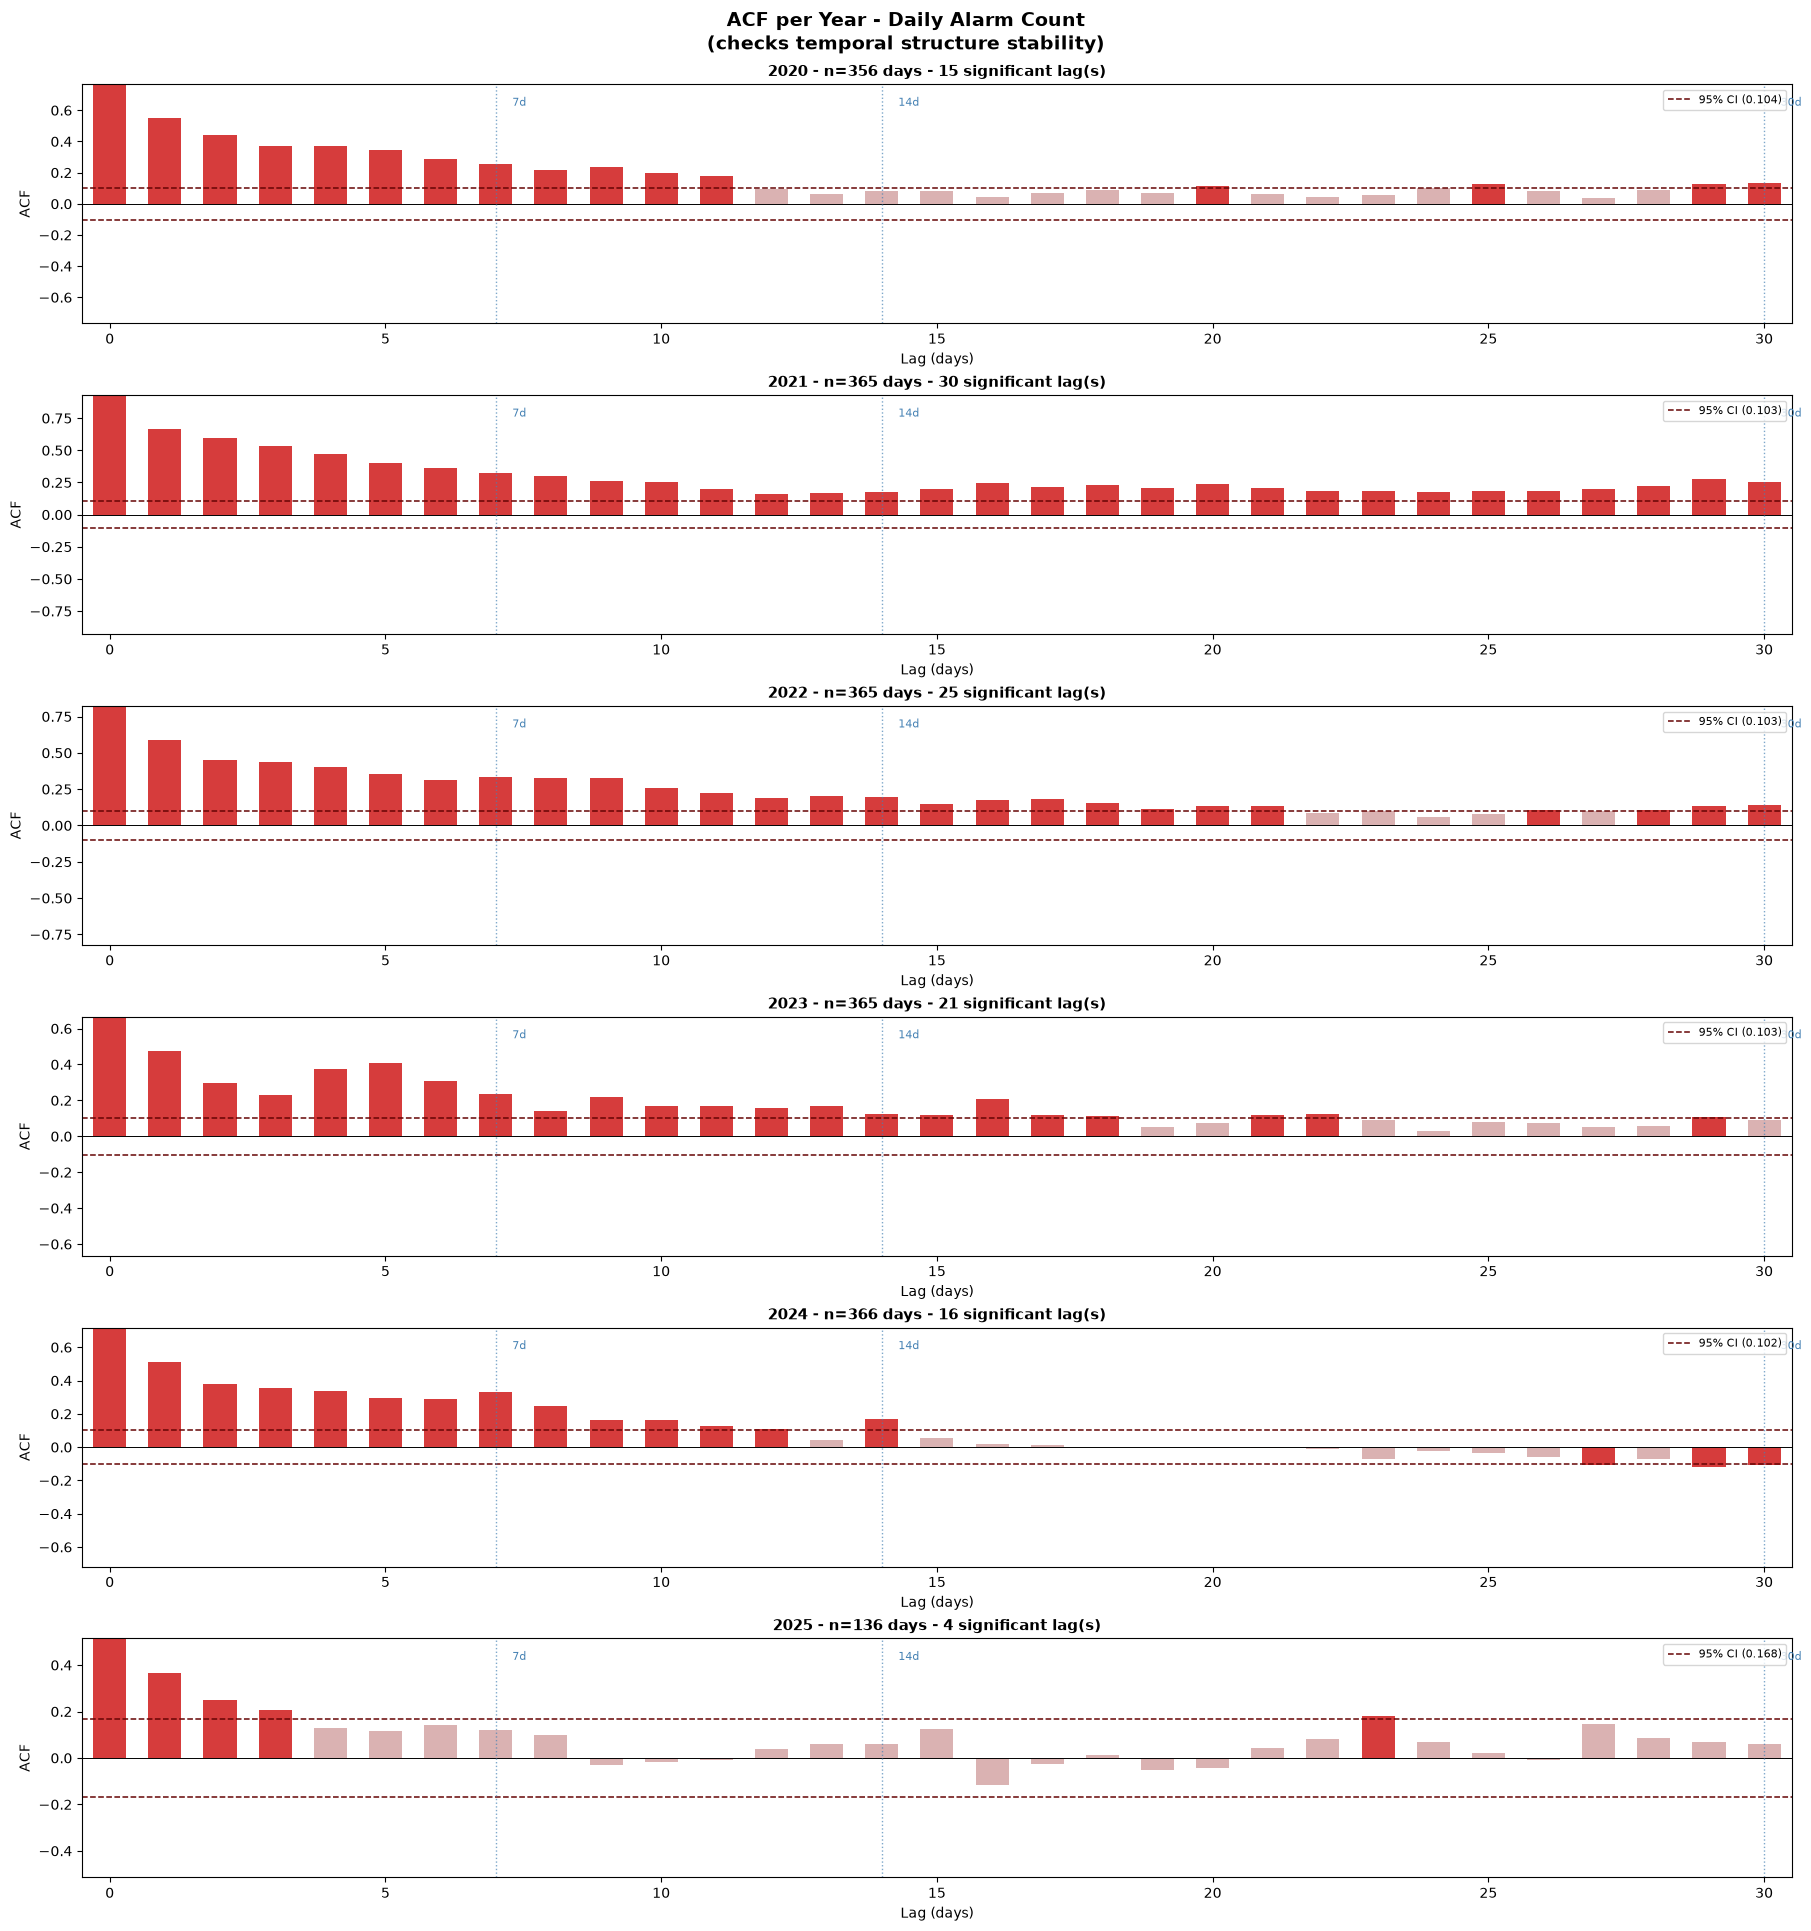

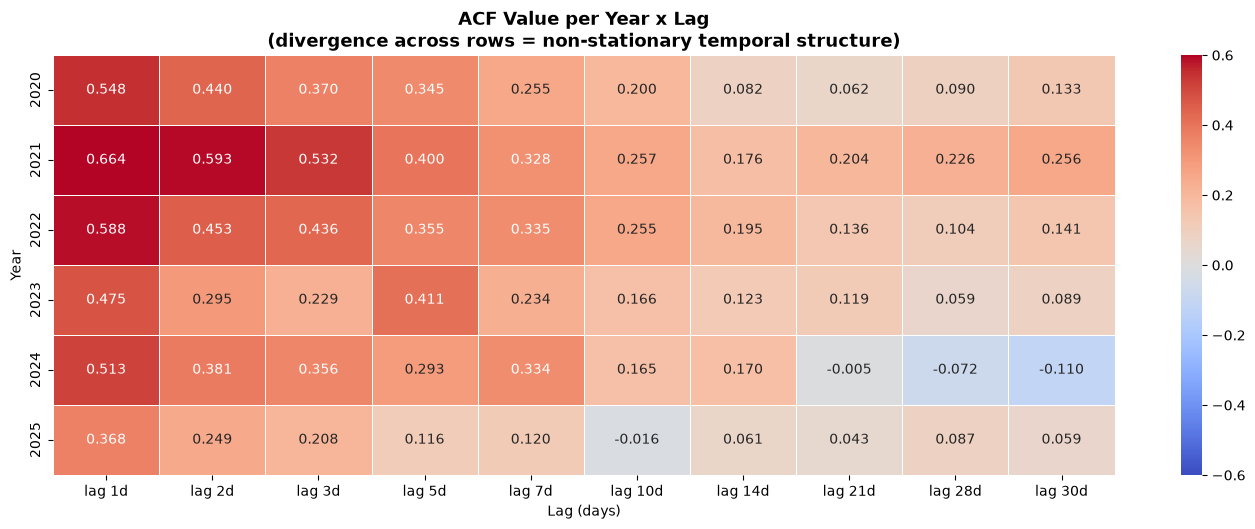

[LOG] ACF @ key lags per year:
      lag 1d  lag 2d  lag 3d  lag 5d  lag 7d  lag 10d  lag 14d  lag 21d  lag 28d  lag 30d
2020    0.55    0.44    0.37    0.35    0.25     0.20     0.08     0.06     0.09     0.13
2021    0.66    0.59    0.53    0.40    0.33     0.26     0.18     0.20     0.23     0.26
2022    0.59    0.45    0.44    0.35    0.34     0.26     0.20     0.14     0.10     0.14
2023    0.48    0.30    0.23    0.41    0.23     0.17     0.12     0.12     0.06     0.09
2024    0.51    0.38    0.36    0.29    0.33     0.17     0.17    -0.00    -0.07    -0.11
2025    0.37    0.25    0.21    0.12    0.12    -0.02     0.06     0.04     0.09     0.06


In [28]:
acf_clean, pacf_clean = plot_acf_pacf(
    daily_agg_ts_no_outliers,
    max_lags=90,
    save_dir='results/eda/correlations/acf/cleaned',
)
acf_year_heatmap_clean, acf_by_year_clean = acf_by_year_heatmap(
    daily_agg_ts_no_outliers,
    save_dir='results/eda/correlations/acf/cleaned',
)

### 4.3 Exogenous Variables

In [29]:
alarms_raw = monthly_alarm_counts(daily_agg_time_series)
alarms_no_outliers = monthly_alarm_counts(daily_agg_ts_no_outliers)

gdp = load_gdp(
    GDP_FILE,
    date_col='Data',
    value_col='Valor',
)
selic = load_selic(SELIC_FILE)
trade_balance = load_trade_balance(TRADE_BALANCE_FILE)
ipca_duraveis = load_ipca_duraveis(
    IPCA_DURAVEIS_FILE,
    date_col='Data',
    value_col='IPCA_Duraveis',
)

df_econ_raw = alarms_raw.merge(selic, on='AnoMes', how='inner')
df_econ_raw = df_econ_raw.merge(gdp, on='AnoMes', how='inner')
df_econ_raw = df_econ_raw.merge(trade_balance, on='AnoMes', how='inner')
df_econ_raw = df_econ_raw.merge(ipca_duraveis, on='AnoMes', how='inner')

df_econ_cleaned = alarms_no_outliers.merge(selic, on='AnoMes', how='inner')
df_econ_cleaned = df_econ_cleaned.merge(gdp, on='AnoMes', how='inner')
df_econ_cleaned = df_econ_cleaned.merge(trade_balance, on='AnoMes', how='inner')
df_econ_cleaned = df_econ_cleaned.merge(ipca_duraveis, on='AnoMes', how='inner')

display(df_econ_raw.head())
display(df_econ_cleaned.head())

[LOG] Monthly alarm counts: 65 months
[LOG] Monthly alarm counts: 65 months
[LOG] GDP loaded: 67 months, 0 missing values
[LOG] SELIC loaded: 1400 daily records -> 67 months (0 unparsable values)
[LOG] Trade Balance loaded: 66 months, 0 missing values
[LOG] IPCA de Duráveis loaded: 421 months, 0 missing values


,AnoMes,Qty_Alarms,Media_Selic,PIB,Trade_Balance,IPCA_Duraveis
0,2020-01,1395,0.02,7424404.30,-3642.10,0.15
1,2020-01,1395,0.02,7498083.30,-3642.10,0.15
2,2020-02,1520,0.02,7466135.30,702.50,0.02
3,2020-03,1361,0.02,7499672.00,1902.50,-0.20
4,2020-04,0,0.01,7453770.80,4618.70,-0.87


,AnoMes,Qty_Alarms,Media_Selic,PIB,Trade_Balance,IPCA_Duraveis
0,2020-01,1279.00,0.02,7424404.30,-3642.10,0.15
1,2020-01,1279.00,0.02,7498083.30,-3642.10,0.15
2,2020-02,1295.00,0.02,7466135.30,702.50,0.02
3,2020-03,1171.50,0.02,7499672.00,1902.50,-0.20
4,2020-04,0.00,0.01,7453770.80,4618.70,-0.87


Raw Alarms Data Correlation

[LOG] Spearman correlation (Media_Selic vs Qty_Alarms): -0.489 (p=0.00005)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_Media_Selic_x_Qty_Alarms_raw.png


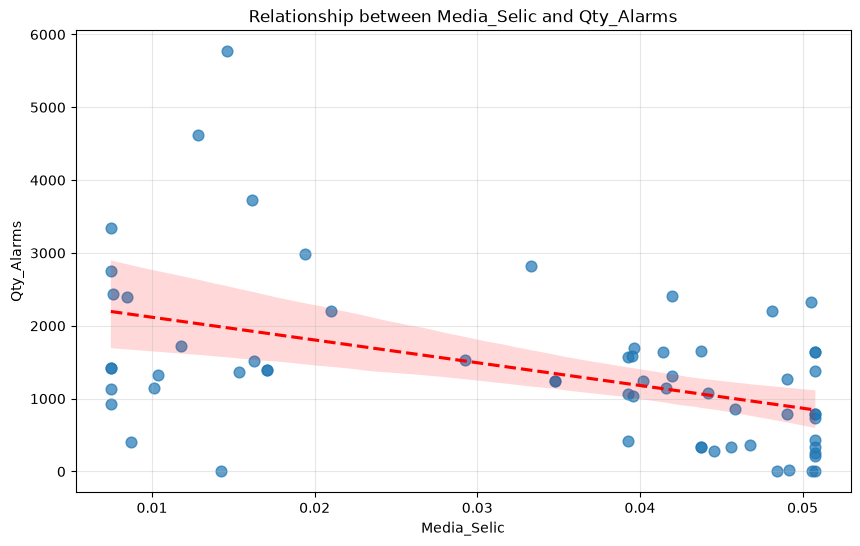

[LOG] Spearman correlation (PIB vs Qty_Alarms): -0.359 (p=0.00382)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_PIB_x_Qty_Alarms_raw.png


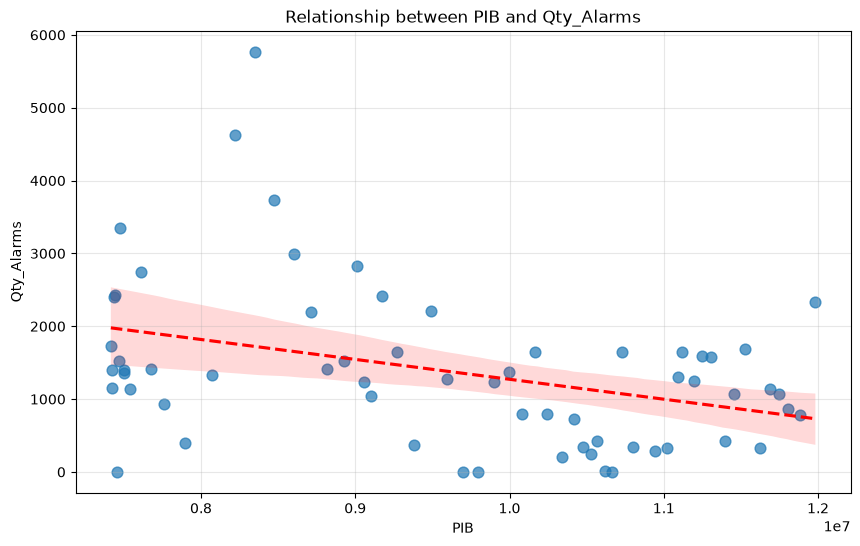

[LOG] Spearman correlation (Trade_Balance vs Qty_Alarms): -0.119 (p=0.35232)
[LOG] Not statistically significant
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_Trade_Balance_x_Qty_Alarms_raw.png


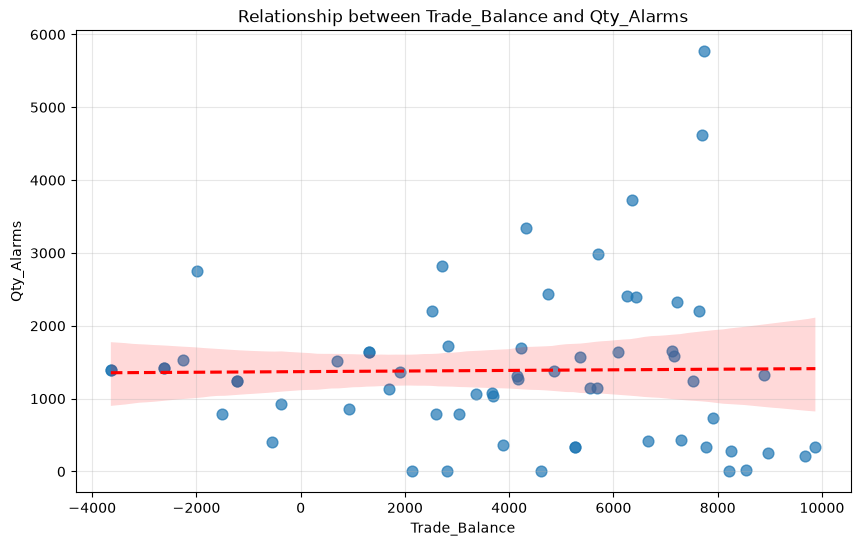

[LOG] Spearman correlation (IPCA_Duraveis vs Qty_Alarms): 0.434 (p=0.00038)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_IPCA_Duraveis_x_Qty_Alarms_raw.png


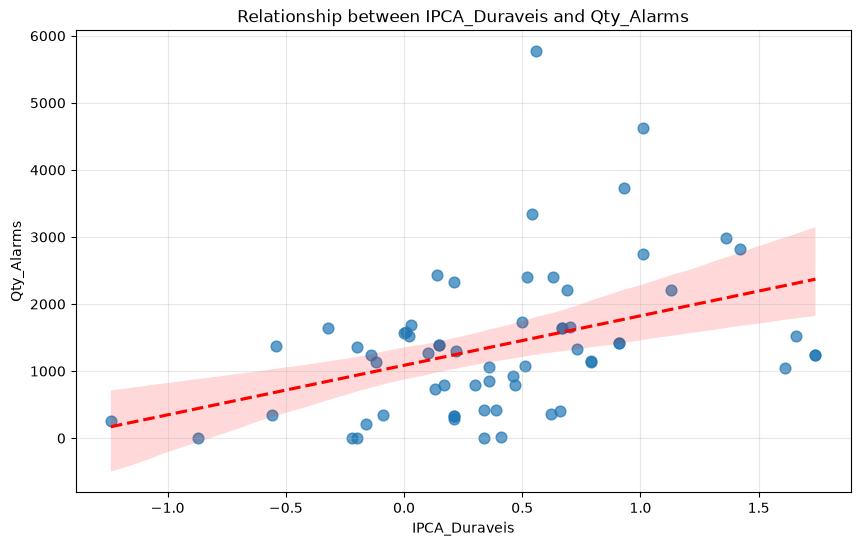

In [30]:
for var in ['Media_Selic', 'PIB', 'Trade_Balance', 'IPCA_Duraveis']:
      correlation_pvalue(df_econ_raw, x=var, y='Qty_Alarms', method='spearman')
      plot_regression(df_econ_raw, x=var, y='Qty_Alarms', save_path=f"results/eda/correlation/exogenous_vars/regression_{var}_x_Qty_Alarms_raw.png")

Checks for temporal lagged correlation

[LOG] Lag correlation (spearman) computed for 4 variable(s) across lags -3 to 3
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/lag_correlation_analysis_raw.png


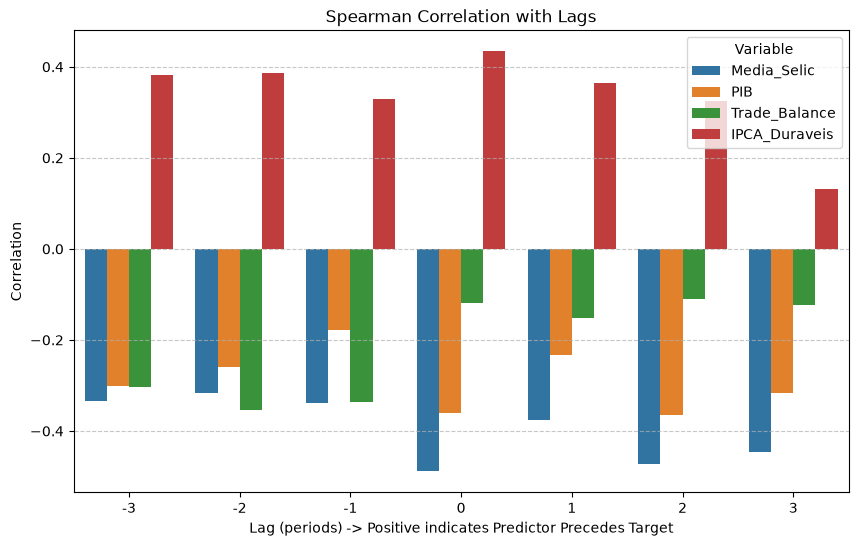

In [31]:
df_lags = lag_correlation_analysis(
        df_econ_raw,
        target='Qty_Alarms',
        predictors=['Media_Selic', 'PIB', 'Trade_Balance', 'IPCA_Duraveis'],
        method='spearman', save_path="results/eda/correlation/exogenous_vars/lag_correlation_analysis_raw.png")

Cleaned Alarms Data Correlation

[LOG] Spearman correlation (Media_Selic vs Qty_Alarms): -0.410 (p=0.00085)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_Media_Selic_x_Qty_Alarms_cleaned.png


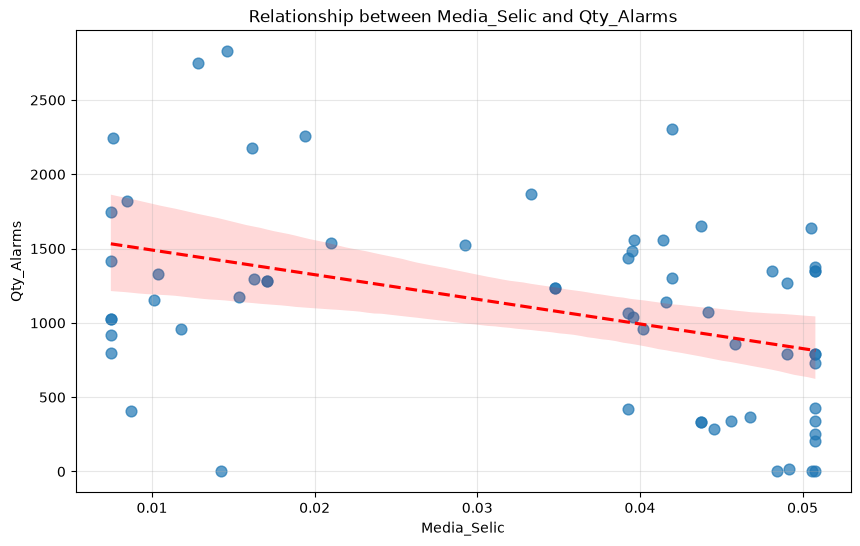

[LOG] Spearman correlation (PIB vs Qty_Alarms): -0.267 (p=0.03438)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_PIB_x_Qty_Alarms_cleaned.png


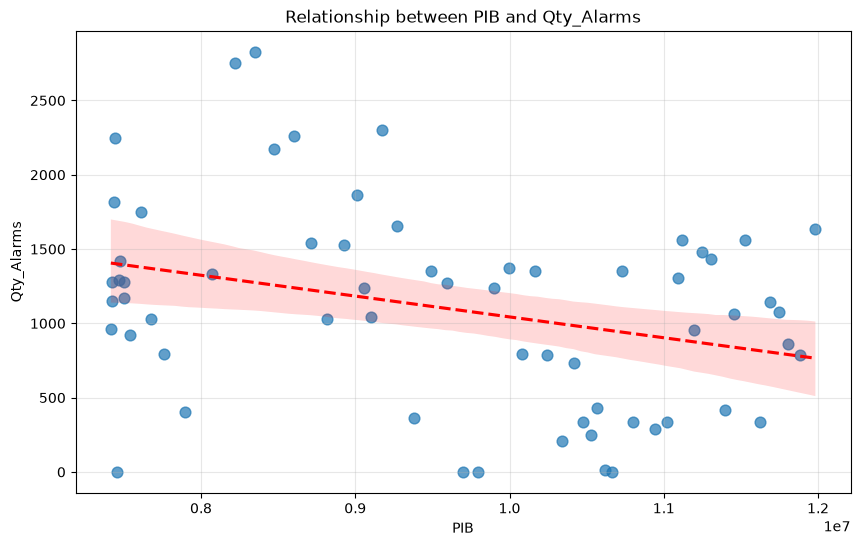

[LOG] Spearman correlation (Trade_Balance vs Qty_Alarms): -0.075 (p=0.56048)
[LOG] Not statistically significant
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_Trade_Balance_x_Qty_Alarms_cleaned.png


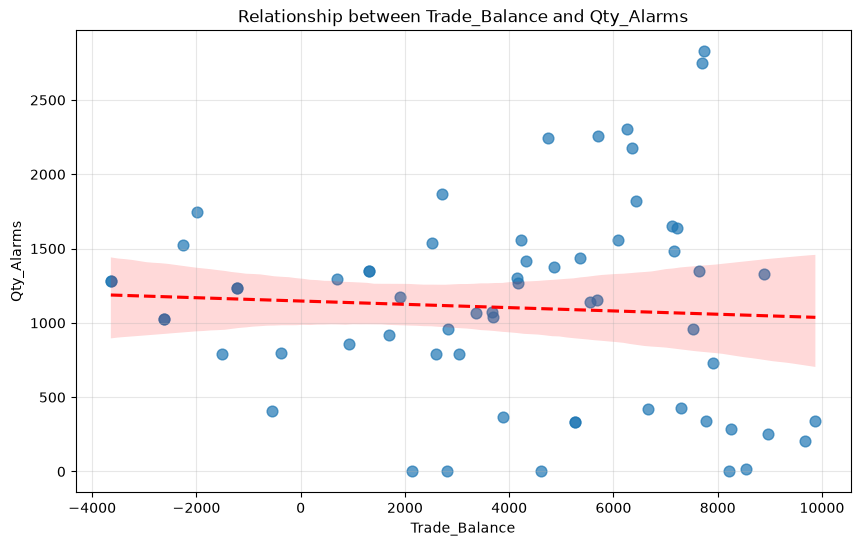

[LOG] Spearman correlation (IPCA_Duraveis vs Qty_Alarms): 0.401 (p=0.00113)
[LOG] Statistically significant (p < 0.05)
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/regression_IPCA_Duraveis_x_Qty_Alarms_cleaned.png


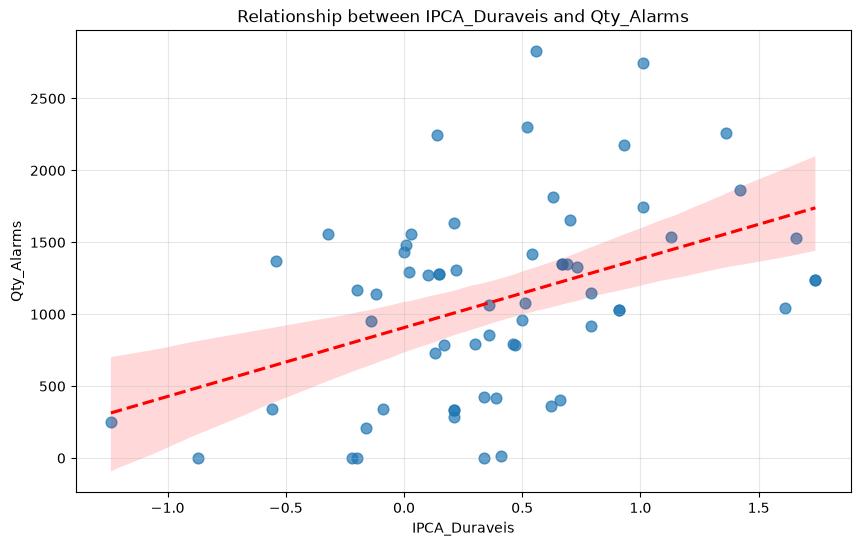

In [32]:
for var in ['Media_Selic', 'PIB', 'Trade_Balance', 'IPCA_Duraveis']:
      correlation_pvalue(df_econ_cleaned, x=var, y='Qty_Alarms', method='spearman')
      plot_regression(df_econ_cleaned, x=var, y='Qty_Alarms', save_path=f"results/eda/correlation/exogenous_vars/regression_{var}_x_Qty_Alarms_cleaned.png")

[LOG] Lag correlation (spearman) computed for 4 variable(s) across lags -3 to 3
[LOG] Plot saved to: results/eda/correlation/exogenous_vars/lag_correlation_analysis_cleaned.png


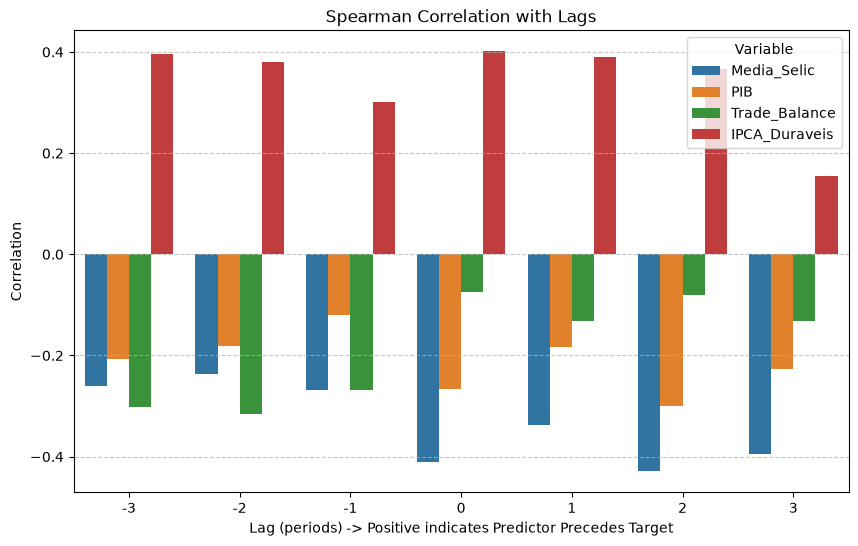

In [33]:
df_lags = lag_correlation_analysis(
        df_econ_cleaned,
        target='Qty_Alarms',
        predictors=['Media_Selic', 'PIB', 'Trade_Balance', 'IPCA_Duraveis'],
        method='spearman', save_path="results/eda/correlation/exogenous_vars/lag_correlation_analysis_cleaned.png")

## Feature Engineering

The construction of the simple and complete feature datasets is now maintained in the standalone notebook `build_feats_pipeline.ipynb`.